In [1]:
# Cell 1.1: Thiết lập môi trường, seed và cấu trúc thư mục lưu trữ cho NB03
import os
import sys
import json
import random
import subprocess
import numpy as np

# 1. Tự động kiểm tra và cài đặt thư viện cho bài toán RL (Google Colab / Kaggle / Local)
required_packages = ["gymnasium==0.29.1", "pyyaml==6.0.1"]
for pkg in required_packages:
    pkg_name = pkg.split("==")[0]
    try:
        __import__(pkg_name)
    except ImportError:
        print(f"Đang cài đặt thư viện {pkg}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

# 2. Cố định Random Seed trên toàn hệ thống
SEED = 42

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

# 3. Tạo cấu trúc thư mục lưu trữ artifacts của NB03
OUTPUT_DIRS = [
    "outputs/models",
    "outputs/figures",
    "outputs/metrics"
]
for d in OUTPUT_DIRS:
    os.makedirs(d, exist_ok=True)

# 4. In thông tin môi trường thực thi
import gymnasium as gym
import yaml

print("=== MÔI TRƯỜNG THỰC THI NOTEBOOK 03 (REINFORCEMENT LEARNING) ===")
print(f"Python version     : {sys.version.split()[0]}")
print(f"Gymnasium version  : {gym.__version__}")
print(f"PyYAML version     : {yaml.__version__}")
print(f"NumPy version      : {np.__version__}")
print(f"Trạng thái         : Đã tạo xong outputs/ và cố định SEED = {SEED}.")

Đang cài đặt thư viện gymnasium==0.29.1...
Đang cài đặt thư viện pyyaml==6.0.1...
=== MÔI TRƯỜNG THỰC THI NOTEBOOK 03 (REINFORCEMENT LEARNING) ===
Python version     : 3.11.16
Gymnasium version  : 0.29.1
PyYAML version     : 6.0.1
NumPy version      : 2.4.6
Trạng thái         : Đã tạo xong outputs/ và cố định SEED = 42.


In [2]:
# Cell 1.2: Tạo và lưu trữ tệp cấu hình luật an toàn y tế (rules.yaml)
rules_yaml_content = """# rules.yaml - Hệ thống luật an toàn y khoa kiểm soát đề xuất lối sống
# Nguồn dẫn chiếu: Quyết định 5481/QĐ-BYT (Bộ Y tế) và ADA Standards of Care

safety_rules:
  rule_01_hypo_exercise_veto:
    id: "RULE_01_HYPO_NO_EXERCISE"
    description: "Cấm vận động thể lực khi đường huyết dưới 100 mg/dL (đặc biệt nguy hiểm dưới 70 mg/dL)"
    condition: "glucose < 100"
    forbidden_exercise: ["MODERATE", "HIGH"]
    penalty: 50.0
    source: "QĐ 5481/QĐ-BYT Phần 4, Mục 5.2 (trang 28)"

  rule_02_hyper_exercise_veto:
    id: "RULE_02_HYPER_NO_EXERCISE"
    description: "Không tập thể dục cường độ vừa/cao khi đường huyết trên 250 mg/dL (nguy cơ toan ceton)"
    condition: "glucose > 250"
    forbidden_exercise: ["MODERATE", "HIGH"]
    penalty: 50.0
    source: "QĐ 5481/QĐ-BYT Phần 4, Mục 5.2"

  rule_03_hyper_restrict_carb:
    id: "RULE_03_HYPER_RESTRICT_CARB"
    description: "Khi đường huyết trên 180 mg/dL, cấm đề xuất bữa ăn mức tinh bột cao (High Carb)"
    condition: "glucose > 180"
    forbidden_carb: ["HIGH"]
    penalty: 30.0
    source: "ADA Lifestyle Management & QĐ 5481 Bảng 4"

  rule_04_hypo_require_carb:
    id: "RULE_04_HYPO_REQUIRE_CARB"
    description: "Khi đường huyết dưới 80 mg/dL, cấm đề xuất bữa ăn cắt kiệt tinh bột (Low Carb)"
    condition: "glucose < 80"
    forbidden_carb: ["LOW"]
    penalty: 40.0
    source: "NIDDK Hypoglycemia & Quy tắc 15-15"

  rule_05_mandatory_monitoring:
    id: "RULE_05_MANDATORY_MONITORING"
    description: "Bắt buộc kích hoạt nhắc đo đường huyết khi chỉ số rơi vào vùng bất thường (< 70 mg/dL hoặc > 250 mg/dL)"
    condition: "glucose < 70 or glucose > 250"
    required_remind: true
    penalty: 25.0
    source: "QĐ 5481/QĐ-BYT Phần 10 & NIDDK Emergency"

  rule_06_absolute_no_medication:
    id: "RULE_06_NO_MEDICATION_IN_RL"
    description: "Phạm vi tuyệt đối: Không gian hành động của RL chỉ bao gồm lối sống, nghiêm cấm kê đơn hoặc chỉnh liều thuốc/insulin"
    enforced_by_design: true
    source: "Phạm vi đồ án PTIT & QĐ 5481/QĐ-BYT Phần 6"
"""

rules_file_path = "rules.yaml"
with open(rules_file_path, "w", encoding="utf-8") as f:
    f.write(rules_yaml_content)

print(f"=== ĐÃ TẠO TỆP QUY TẮC AN TOÀN LÂM SÀNG: {rules_file_path} ===")
with open(rules_file_path, "r", encoding="utf-8") as f:
    loaded_rules = yaml.safe_load(f)
print(f"Tổng số luật an toàn được nạp: {len(loaded_rules['safety_rules'])} quy tắc.")
for k, v in loaded_rules['safety_rules'].items():
    print(f"- [{v['id']}]: {v['description']} (Nguồn: {v['source']})")

=== ĐÃ TẠO TỆP QUY TẮC AN TOÀN LÂM SÀNG: rules.yaml ===
Tổng số luật an toàn được nạp: 6 quy tắc.
- [RULE_01_HYPO_NO_EXERCISE]: Cấm vận động thể lực khi đường huyết dưới 100 mg/dL (đặc biệt nguy hiểm dưới 70 mg/dL) (Nguồn: QĐ 5481/QĐ-BYT Phần 4, Mục 5.2 (trang 28))
- [RULE_02_HYPER_NO_EXERCISE]: Không tập thể dục cường độ vừa/cao khi đường huyết trên 250 mg/dL (nguy cơ toan ceton) (Nguồn: QĐ 5481/QĐ-BYT Phần 4, Mục 5.2)
- [RULE_03_HYPER_RESTRICT_CARB]: Khi đường huyết trên 180 mg/dL, cấm đề xuất bữa ăn mức tinh bột cao (High Carb) (Nguồn: ADA Lifestyle Management & QĐ 5481 Bảng 4)
- [RULE_04_HYPO_REQUIRE_CARB]: Khi đường huyết dưới 80 mg/dL, cấm đề xuất bữa ăn cắt kiệt tinh bột (Low Carb) (Nguồn: NIDDK Hypoglycemia & Quy tắc 15-15)
- [RULE_05_MANDATORY_MONITORING]: Bắt buộc kích hoạt nhắc đo đường huyết khi chỉ số rơi vào vùng bất thường (< 70 mg/dL hoặc > 250 mg/dL) (Nguồn: QĐ 5481/QĐ-BYT Phần 10 & NIDDK Emergency)
- [RULE_06_NO_MEDICATION_IN_RL]: Phạm vi tuyệt đối: Không gian hành độ

In [3]:
# Cell 1.3: Bảng đặc tả giả định sinh lý học, căn cứ tham số và tuyên bố miễn trừ y tế
import pandas as pd

assumptions_and_parameters = [
    {
        "Thành phần / Tham số": "Mục tiêu đường huyết an toàn (Target Range)",
        "Giá trị mô phỏng": "80 - 130 mg/dL (trước ăn), < 180 mg/dL (đỉnh sau ăn)",
        "Phân loại cơ sở": "CĂN CỨ TÀI LIỆU Y KHOA ĐÃ GỬI",
        "Nguồn kiểm chứng": "QĐ 5481/QĐ-BYT Bảng 4 & ADA Standards 2026 Mục 1",
        "Ghi chú lâm sàng": "Khoảng mục tiêu kiểm soát tối ưu để phòng ngừa biến chứng vi mạch và hạ đường huyết."
    },
    {
        "Thành phần / Tham số": "Ngưỡng hạ đường huyết cấp tính (Hypoglycemia)",
        "Giá trị mô phỏng": "< 70 mg/dL (< 3.9 mmol/L)",
        "Phân loại cơ sở": "CĂN CỨ TÀI LIỆU Y KHOA ĐÃ GỬI",
        "Nguồn kiểm chứng": "NIDDK Guidelines Mục 1 & QĐ 5481 Phần 6",
        "Ghi chú lâm sàng": "Ngưỡng cảnh báo bắt buộc kích hoạt Quy tắc 15-15 và cấm tuyệt đối vận động thể lực."
    },
    {
        "Thành phần / Tham số": "Ngưỡng cấm tập thể dục do đường huyết cao",
        "Giá trị mô phỏng": "> 250 mg/dL (> 14.0 mmol/L)",
        "Phân loại cơ sở": "CĂN CỨ TÀI LIỆU Y KHOA ĐÃ GỬI",
        "Nguồn kiểm chứng": "QĐ 5481/QĐ-BYT Phần 4, Mục 5.2 (trang 28)",
        "Ghi chú lâm sàng": "Vận động khi đường huyết > 250 mg/dL kích thích phân giải glycogen gan và làm tăng nguy cơ toan ceton."
    },
    {
        "Thành phần / Tham số": "Phạm vi hành động (Action Scope)",
        "Giá trị mô phỏng": "Chỉ gồm: Mức tinh bột bữa ăn, Mức vận động, Nhắc đo đường huyết",
        "Phân loại cơ sở": "CĂN CỨ TÀI LIỆU Y KHOA ĐÃ GỬI",
        "Nguồn kiểm chứng": "Đề cương đồ án & QĐ 5481 Phần 4 (Dinh dưỡng & Thể lực)",
        "Ghi chú lâm sàng": "TUYỆT ĐỐI không có hành động kê đơn hoặc chỉnh liều thuốc/insulin."
    },
    {
        "Thành phần / Tham số": "Mức tăng đường huyết do tinh bột (Delta Carb)",
        "Giá trị mô phỏng": "Low: +15~25, Mod: +35~50, High: +70~95 mg/dL",
        "Phân loại cơ sở": "GIẢ ĐỊNH KỸ THUẬT TỰ ĐẶT (Ước lượng chuyển hóa)",
        "Nguồn kiểm chứng": "Giả lập theo chỉ số Glycemic Load lý thuyết",
        "Ghi chú kỹ thuật": "Mô phỏng mức tăng glucose huyết tương sau bữa ăn tương ứng với 30g, 55g và 90g carbohydrate."
    },
    {
        "Thành phần / Tham số": "Mức hạ đường huyết do vận động (Delta Exercise)",
        "Giá trị mô phỏng": "None: 0, Moderate: -25 ~ -42 mg/dL",
        "Phân loại cơ sở": "GIẢ ĐỊNH KỸ THUẬT TỰ ĐẶT (Ước lượng chuyển hóa)",
        "Nguồn kiểm chứng": "Giả lập theo mức tiêu hao glucose cơ bắp 30 phút",
        "Ghi chú kỹ thuật": "Phản ánh sự gia tăng độ nhạy insulin và tiêu thụ glucose qua co cơ khi đi bộ nhanh."
    },
    {
        "Thành phần / Tham số": "Lực kéo cân bằng nội môi cơ bản (Basal Drift)",
        "Giá trị mô phỏng": "-0.15 * (Glucose - 120 mg/dL)",
        "Phân loại cơ sở": "GIẢ ĐỊNH KỸ THUẬT TỰ ĐẶT (Toán học mô phỏng)",
        "Nguồn kiểm chứng": "Phương trình cân bằng nội môi dịch chuyển tiệm cận",
        "Ghi chú kỹ thuật": "Mô phỏng hoạt động bài tiết insulin nền và tân tạo đường của gan nhằm kéo đường huyết về điểm cân bằng."
    },
    {
        "Thành phần / Tham số": "Nhiễu sinh học ngẫu nhiên (Metabolic Noise)",
        "Giá trị mô phỏng": "epsilon ~ Normal(0, sigma^2), sigma = 5.0 mg/dL",
        "Phân loại cơ sở": "GIẢ ĐỊNH KỸ THUẬT TỰ ĐẶT (Mô hình Markov ngẫu nhiên)",
        "Nguồn kiểm chứng": "Biến thiên sinh học thực nghiệm",
        "Ghi chú kỹ thuật": "Đại diện cho stress, cảm xúc và sai số đo của thiết bị đo mao mạch."
    }
]

df_assumptions = pd.DataFrame(assumptions_and_parameters)
print("=== BẢNG ĐỐI CHIẾU CĂN CỨ VÀ GIẢ ĐỊNH THAM SỐ MÔ HÌNH SINH LÝ ===")
display(df_assumptions[["Thành phần / Tham số", "Giá trị mô phỏng", "Phân loại cơ sở", "Nguồn kiểm chứng"]])

print("\n" + "="*80)
print("TUYÊN BỐ MIỄN TRỪ TRÁCH NHIỆM Y TẾ (ACADEMIC DISCLAIMER):")
print("Môi trường này là một mô hình giả lập toán học phục vụ nghiên cứu thuật toán Học tăng cường")
print("trong khuôn khổ đồ án học thuật PTIT. ĐÂY KHÔNG PHẢI LÀ BỆNH NHÂN THẬT.")
print("Mọi giá trị đường huyết sinh ra chỉ phản ánh tính tương tác của phương trình toán học giả định,")
print("tuyệt đối không được sử dụng để suy diễn phác đồ điều trị hay áp dụng trên người thực tế.")
print("="*80)

=== BẢNG ĐỐI CHIẾU CĂN CỨ VÀ GIẢ ĐỊNH THAM SỐ MÔ HÌNH SINH LÝ ===


,Thành phần / Tham số,Giá trị mô phỏng,Phân loại cơ sở,Nguồn kiểm chứng
0,Mục tiêu đường huyết an toàn (Target Range),"80 - 130 mg/dL (trước ăn), < 180 mg/dL (đỉnh s...",CĂN CỨ TÀI LIỆU Y KHOA ĐÃ GỬI,QĐ 5481/QĐ-BYT Bảng 4 & ADA Standards 2026 Mục 1
1,Ngưỡng hạ đường huyết cấp tính (Hypoglycemia),< 70 mg/dL (< 3.9 mmol/L),CĂN CỨ TÀI LIỆU Y KHOA ĐÃ GỬI,NIDDK Guidelines Mục 1 & QĐ 5481 Phần 6
2,Ngưỡng cấm tập thể dục do đường huyết cao,> 250 mg/dL (> 14.0 mmol/L),CĂN CỨ TÀI LIỆU Y KHOA ĐÃ GỬI,"QĐ 5481/QĐ-BYT Phần 4, Mục 5.2 (trang 28)"
3,Phạm vi hành động (Action Scope),"Chỉ gồm: Mức tinh bột bữa ăn, Mức vận động, Nh...",CĂN CỨ TÀI LIỆU Y KHOA ĐÃ GỬI,Đề cương đồ án & QĐ 5481 Phần 4 (Dinh dưỡng & ...
4,Mức tăng đường huyết do tinh bột (Delta Carb),"Low: +15~25, Mod: +35~50, High: +70~95 mg/dL",GIẢ ĐỊNH KỸ THUẬT TỰ ĐẶT (Ước lượng chuyển hóa),Giả lập theo chỉ số Glycemic Load lý thuyết
5,Mức hạ đường huyết do vận động (Delta Exercise),"None: 0, Moderate: -25 ~ -42 mg/dL",GIẢ ĐỊNH KỸ THUẬT TỰ ĐẶT (Ước lượng chuyển hóa),Giả lập theo mức tiêu hao glucose cơ bắp 30 phút
6,Lực kéo cân bằng nội môi cơ bản (Basal Drift),-0.15 * (Glucose - 120 mg/dL),GIẢ ĐỊNH KỸ THUẬT TỰ ĐẶT (Toán học mô phỏng),Phương trình cân bằng nội môi dịch chuyển tiệm...
7,Nhiễu sinh học ngẫu nhiên (Metabolic Noise),"epsilon ~ Normal(0, sigma^2), sigma = 5.0 mg/dL",GIẢ ĐỊNH KỸ THUẬT TỰ ĐẶT (Mô hình Markov ngẫu ...,Biến thiên sinh học thực nghiệm



TUYÊN BỐ MIỄN TRỪ TRÁCH NHIỆM Y TẾ (ACADEMIC DISCLAIMER):
Môi trường này là một mô hình giả lập toán học phục vụ nghiên cứu thuật toán Học tăng cường
trong khuôn khổ đồ án học thuật PTIT. ĐÂY KHÔNG PHẢI LÀ BỆNH NHÂN THẬT.
Mọi giá trị đường huyết sinh ra chỉ phản ánh tính tương tác của phương trình toán học giả định,
tuyệt đối không được sử dụng để suy diễn phác đồ điều trị hay áp dụng trên người thực tế.


In [4]:
# Cell 1.4: Xây dựng môi trường Gymnasium tùy biến DiabetesLifestyleEnv
import gymnasium as gym
from gymnasium import spaces
import numpy as np

class DiabetesLifestyleEnv(gym.Env):
    """
    Môi trường Gymnasium mô phỏng động học đường huyết bệnh nhân đái tháo đường típ 2
    trước các can thiệp lối sống (Carb bữa ăn, Vận động, Nhắc đo đường huyết).
    """
    metadata = {"render_modes": ["human"]}

    def __init__(self, rules_dict=None):
        super().__init__()
        self.rules = rules_dict or {}

        # 1. Không gian hành động kết hợp (12 Discrete Actions):
        # 3 mức Carb x 2 mức Vận động x 2 lựa chọn Nhắc đo
        self.action_definitions = []
        for c in ["LOW", "MODERATE", "HIGH"]:
            for e in ["NONE", "MODERATE"]:
                for r in [False, True]:
                    self.action_definitions.append({
                        "action_id": len(self.action_definitions),
                        "carb": c,
                        "exercise": e,
                        "remind": r,
                        "label": f"Carb:{c} | Ex:{e} | Remind:{r}"
                    })
        self.action_space = spaces.Discrete(len(self.action_definitions))

        # 2. Không gian quan sát liên tục: [Nồng độ Glucose (mg/dL), Thời điểm trong ngày (0..3)]
        self.observation_space = spaces.Box(
            low=np.array([40.0, 0.0], dtype=np.float32),
            high=np.array([400.0, 3.0], dtype=np.float32),
            dtype=np.float32
        )

        self.glucose = 120.0
        self.step_idx = 0
        self.max_steps = 4  # Một chu kỳ ngày gồm 4 thời điểm: Sáng, Trưa, Tối, Đêm
        self.rng = np.random.default_rng(SEED)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        if seed is not None:
            self.rng = np.random.default_rng(seed)
        
        # Khởi tạo đường huyết đầu ngày ngẫu nhiên trong khoảng 95 đến 165 mg/dL
        self.glucose = float(self.rng.uniform(95.0, 165.0))
        self.step_idx = 0
        obs = np.array([self.glucose, float(self.step_idx)], dtype=np.float32)
        return obs, {}

    def step(self, action_idx: int):
        action_dict = self.action_definitions[action_idx]
        prev_glucose = self.glucose
        
        # --- ĐỘNG HỌC CHUYỂN HÓA GLUCOSE ---
        carb_impacts = {
            "LOW": self.rng.uniform(15.0, 25.0),
            "MODERATE": self.rng.uniform(35.0, 50.0),
            "HIGH": self.rng.uniform(70.0, 95.0)
        }
        exercise_impacts = {
            "NONE": 0.0,
            "MODERATE": -float(self.rng.uniform(25.0, 42.0))
        }
        basal_drift = -0.15 * (prev_glucose - 120.0)
        metabolic_noise = float(self.rng.normal(0.0, 5.0))

        delta_g = carb_impacts[action_dict["carb"]] + exercise_impacts[action_dict["exercise"]] + basal_drift + metabolic_noise
        self.glucose = float(np.clip(prev_glucose + delta_g, 40.0, 380.0))

        # --- TÍNH PHẦN THƯỞNG VÀ CHẾ TÀI PHẠT LUẬT AN TOÀN ---
        reward = 0.0
        violations = []

        # a. Điểm lâm sàng dựa trên mức đường huyết đạt được
        if 80.0 <= self.glucose <= 140.0:
            reward += 10.0 - 0.05 * abs(self.glucose - 110.0)  # Trong ngưỡng an toàn (TIR)
        elif 140.0 < self.glucose <= 180.0:
            reward += 2.0  # Tăng nhẹ sau ăn, chấp nhận được
        elif 70.0 <= self.glucose < 80.0:
            reward -= 5.0  # Mấp mé hạ đường huyết
        elif self.glucose < 70.0:
            reward -= 30.0 # Hạ đường huyết nguy hiểm
        elif self.glucose > 250.0:
            reward -= 20.0 # Tăng đường huyết rất cao
        else: # 180 < glucose <= 250
            reward -= 10.0

        # b. Kiểm tra các điều cấm trong rules.yaml
        c_act = action_dict["carb"]
        e_act = action_dict["exercise"]
        r_act = action_dict["remind"]

        # Rule 1: Cấm vận động khi đường huyết < 100 mg/dL
        if prev_glucose < 100.0 and e_act != "NONE":
            violations.append("RULE_01_HYPO_NO_EXERCISE")
            reward -= 50.0

        # Rule 2: Cấm vận động nặng khi đường huyết > 250 mg/dL
        if prev_glucose > 250.0 and e_act != "NONE":
            violations.append("RULE_02_HYPER_NO_EXERCISE")
            reward -= 50.0

        # Rule 3: Cấm ăn High Carb khi đường huyết > 180 mg/dL
        if prev_glucose > 180.0 and c_act == "HIGH":
            violations.append("RULE_03_HYPER_RESTRICT_CARB")
            reward -= 30.0

        # Rule 4: Cấm cắt kiệt tinh bột Low Carb khi đường huyết < 80 mg/dL
        if prev_glucose < 80.0 and c_act == "LOW":
            violations.append("RULE_04_HYPO_REQUIRE_CARB")
            reward -= 40.0

        # Rule 5: Bắt buộc nhắc đo đường huyết khi chỉ số bất thường (< 70 hoặc > 250)
        if (prev_glucose < 70.0 or prev_glucose > 250.0) and not r_act:
            violations.append("RULE_05_MANDATORY_MONITORING")
            reward -= 25.0

        # Phạt nhẹ nếu lạm dụng nhắc đo đường huyết khi chỉ số hoàn toàn ổn định (90 - 150 mg/dL)
        if (90.0 <= prev_glucose <= 150.0) and r_act:
            reward -= 1.0

        self.step_idx += 1
        terminated = (self.step_idx >= self.max_steps)
        truncated = False

        obs = np.array([self.glucose, float(min(self.step_idx, 3))], dtype=np.float32)
        info = {
            "prev_glucose": prev_glucose,
            "next_glucose": self.glucose,
            "action": action_dict,
            "violations": violations,
            "in_target_range": (80.0 <= self.glucose <= 140.0)
        }
        return obs, reward, terminated, truncated, info

print("Đã khởi tạo thành công lớp môi trường DiabetesLifestyleEnv.")

Đã khởi tạo thành công lớp môi trường DiabetesLifestyleEnv.


In [5]:
# Cell 1.5: Rời rạc hóa không gian trạng thái và cài đặt hai chính sách đối chuẩn (Baselines)
import numpy as np

def discretize_state(glucose: float, step_idx: int) -> int:
    """
    Ánh xạ [Glucose, Thời điểm] -> Trạng thái rời rạc s in {0, ..., 23}.
    6 khoảng glucose lâm sàng x 4 bước thời gian trong ngày.
    """
    if glucose < 70.0:
        g_bin = 0  # Hạ đường huyết cấp tính
    elif glucose < 100.0:
        g_bin = 1  # Cận bình thường thấp
    elif glucose <= 140.0:
        g_bin = 2  # Khoảng mục tiêu tối ưu (Target Range)
    elif glucose <= 180.0:
        g_bin = 3  # Đỉnh sau ăn chấp nhận được
    elif glucose <= 250.0:
        g_bin = 4  # Tăng đường huyết cao
    else:
        g_bin = 5  # Tăng đường huyết rất cao (Nguy cơ toan ceton)

    time_bin = int(np.clip(step_idx, 0, 3))
    state_id = g_bin * 4 + time_bin
    return state_id

# --- THIẾT KẾ HAI CHÍNH SÁCH ĐỐI CHUẨN (BASELINES) ---

def random_policy(env) -> int:
    """Baseline 1: Chính sách hành động ngẫu nhiên đồng đều."""
    return env.rng.integers(0, env.action_space.n)

def rule_based_clinical_policy(glucose: float, step_idx: int, env) -> int:
    """
    Baseline 2: Chính sách chuyên gia dựa trên hệ luật y khoa tiền định (Rule-Based Agent).
    Ra quyết định lối sống tuân thủ nghiêm ngặt các hướng dẫn an toàn của Bộ Y tế và ADA.
    """
    # 1. Nếu đường huyết thấp (< 100 mg/dL): KHÔNG tập thể dục, ăn Carb vừa phải, nhắc đo nếu < 70
    if glucose < 70.0:
        target_carb, target_ex, target_remind = "MODERATE", "NONE", True
    elif glucose < 100.0:
        target_carb, target_ex, target_remind = "MODERATE", "NONE", False
    # 2. Nếu đường huyết trong khoảng mục tiêu (100 - 140 mg/dL): Duy trì cân bằng, tập thể dục vừa
    elif glucose <= 140.0:
        target_carb, target_ex, target_remind = "MODERATE", "MODERATE", False
    # 3. Nếu đường huyết tăng nhẹ/vừa (141 - 180 mg/dL): Giảm carb, tăng cường vận động
    elif glucose <= 180.0:
        target_carb, target_ex, target_remind = "LOW", "MODERATE", False
    # 4. Nếu đường huyết cao (181 - 250 mg/dL): Ăn Low Carb, vận động vừa, nhắc đo
    elif glucose <= 250.0:
        target_carb, target_ex, target_remind = "LOW", "MODERATE", True
    # 5. Nếu đường huyết rất cao (> 250 mg/dL): Low Carb, KHÔNG tập thể dục (tránh toan ceton), BẮT BUỘC nhắc đo
    else:
        target_carb, target_ex, target_remind = "LOW", "NONE", True

    # Tìm chỉ số action_id tương ứng trong không gian hành động
    for act in env.action_definitions:
        if act["carb"] == target_carb and act["exercise"] == target_ex and act["remind"] == target_remind:
            return act["action_id"]
    return 0

print("=== ĐẶC TẢ RỜI RẠC HÓA VÀ BASELINES ===")
print(f"Tổng số trạng thái rời rạc |S| : 24 trạng thái (6 bins Glucose x 4 bins Thời điểm)")
print(f"Tổng số hành động lối sống |A|  : 12 hành động kết hợp")
print("Đã thiết lập sẵn sàng: Random Policy và Rule-based Clinical Policy.")

=== ĐẶC TẢ RỜI RẠC HÓA VÀ BASELINES ===
Tổng số trạng thái rời rạc |S| : 24 trạng thái (6 bins Glucose x 4 bins Thời điểm)
Tổng số hành động lối sống |A|  : 12 hành động kết hợp
Đã thiết lập sẵn sàng: Random Policy và Rule-based Clinical Policy.


In [6]:
# Cell 1.6: CHỐT GIAO THỨC ĐÁNH GIÁ THỰC NGHIỆM RL (RL Evaluation Protocol Specification)
import json

rl_protocol = {
    "project": "Hệ đa agent hỗ trợ tư vấn cho bệnh nhân tiểu đường - NB03 Reinforcement Learning",
    "problem_formulation": {
        "paradigm": "Markov Decision Process (MDP)",
        "state_space_discrete_cardinality": 24,
        "action_space_discrete_cardinality": 12,
        "episode_horizon": 4,
        "discount_factor_gamma": 0.95
    },
    "algorithm": {
        "name": "Tabular Q-Learning",
        "update_equation": "Q(s, a) <- Q(s, a) + alpha * [r + gamma * max_a' Q(s', a') - Q(s, a)]",
        "learning_rate_alpha": 0.08,
        "exploration_strategy": "Epsilon-Greedy with exponential decay",
        "epsilon_start": 1.0,
        "epsilon_min": 0.02,
        "epsilon_decay": 0.996
    },
    "safety_enforcement": {
        "rules_file": "rules.yaml",
        "safety_penalty_active": True,
        "scope_constraint": "Phạm vi tuyệt đối không bao gồm kê đơn hoặc chỉnh liều thuốc/insulin"
    },
    "evaluation_benchmarks": {
        "baselines": [
            "Baseline 1: Random Policy (Lấy mẫu ngẫu nhiên đồng đều)",
            "Baseline 2: Rule-Based Clinical Policy (Tác tử chuyên gia dựa trên QĐ 5481/QĐ-BYT)"
        ],
        "multi_seed_experiment": {
            "seeds": [42, 101, 2024, 777, 9999],
            "num_seeds": 5
        },
        "training_episodes_per_seed": 1500,
        "evaluation_episodes_deterministic": 200,
        "evaluation_mode": "Pure Exploitation (epsilon = 0.0, Q-table frozen)"
    },
    "core_evaluation_metrics": [
        "mean_episode_reward",
        "rule_violation_rate",
        "time_in_range_ratio (TIR: Tỷ lệ thời gian đường huyết 80-140 mg/dL)"
    ],
    "protocol_immutability": "Giao thức này được chốt bất biến tại Chặng 1, không được thay đổi trong các chặng tiếp theo."
}

protocol_output_path = "outputs/metrics/rl_evaluation_protocol.json"
with open(protocol_output_path, "w", encoding="utf-8") as f:
    json.dump(rl_protocol, f, indent=4, ensure_ascii=False)

print("=== GIAO THỨC ĐÁNH GIÁ THỰC NGHIỆM RL ĐÃ ĐƯỢC CHỐT THÀNH CÔNG ===")
print(f"Tệp lưu trữ giao thức: {protocol_output_path}")
for k, v in rl_protocol.items():
    print(f"- {k}: {v}")

=== GIAO THỨC ĐÁNH GIÁ THỰC NGHIỆM RL ĐÃ ĐƯỢC CHỐT THÀNH CÔNG ===
Tệp lưu trữ giao thức: outputs/metrics/rl_evaluation_protocol.json
- project: Hệ đa agent hỗ trợ tư vấn cho bệnh nhân tiểu đường - NB03 Reinforcement Learning
- problem_formulation: {'paradigm': 'Markov Decision Process (MDP)', 'state_space_discrete_cardinality': 24, 'action_space_discrete_cardinality': 12, 'episode_horizon': 4, 'discount_factor_gamma': 0.95}
- algorithm: {'name': 'Tabular Q-Learning', 'update_equation': "Q(s, a) <- Q(s, a) + alpha * [r + gamma * max_a' Q(s', a') - Q(s, a)]", 'learning_rate_alpha': 0.08, 'exploration_strategy': 'Epsilon-Greedy with exponential decay', 'epsilon_start': 1.0, 'epsilon_min': 0.02, 'epsilon_decay': 0.996}
- safety_enforcement: {'rules_file': 'rules.yaml', 'safety_penalty_active': True, 'scope_constraint': 'Phạm vi tuyệt đối không bao gồm kê đơn hoặc chỉnh liều thuốc/insulin'}
- evaluation_benchmarks: {'baselines': ['Baseline 1: Random Policy (Lấy mẫu ngẫu nhiên đồng đều)', 'B

In [7]:
# Cell 2.1: Kiểm tra tính hợp lệ của giao diện môi trường Gymnasium
import numpy as np

# 1. Khởi tạo môi trường mô phỏng
env = DiabetesLifestyleEnv(rules_dict=loaded_rules.get("safety_rules", {}))

# 2. Kiểm định không gian trạng thái và hành động
print("=== THÔNG SỐ KHÔNG GIAN MÔI TRƯỜNG ===")
print(f"Action Space        : {env.action_space} (Tổng số hành động: {env.action_space.n})")
print(f"Observation Space   : {env.observation_space}")
print(f"Giới hạn quan sát   : Thấp nhất {env.observation_space.low} | Cao nhất {env.observation_space.high}")

# 3. Kiểm định hàm reset()
initial_obs, info_reset = env.reset(seed=SEED)
print("\n=== KẾT QUẢ KIỂM THỬ HÀM RESET() ===")
print(f"Quan sát khởi đầu (Observation): Glucose = {initial_obs[0]:.2f} mg/dL, Bước thời gian = {int(initial_obs[1])}")
print(f"Kiểu dữ liệu quan sát          : {type(initial_obs)} - Shape: {initial_obs.shape} - Dtype: {initial_obs.dtype}")

# 4. Kiểm định hàm step() với một hành động ngẫu nhiên
sample_action = 4  # Action 4: MODERATE Carb + NONE Exercise + Remind:False
next_obs, reward, terminated, truncated, step_info = env.step(sample_action)

print("\n=== KẾT QUẢ KIỂM THỬ HÀM STEP() ===")
print(f"Hành động thực thi (Action {sample_action}) : {step_info['action']['label']}")
print(f"Đường huyết chuyển dịch           : {step_info['prev_glucose']:.2f} -> {step_info['next_glucose']:.2f} mg/dL")
print(f"Phần thưởng nhận được (Reward)    : {reward:.2f}")
print(f"Trạng thái kết thúc (Terminated)  : {terminated}")
print(f"Danh sách vi phạm luật (Safety)   : {step_info['violations']}")
print(f"Nằm trong khoảng an toàn (TIR)    : {step_info['in_target_range']}")

=== THÔNG SỐ KHÔNG GIAN MÔI TRƯỜNG ===
Action Space        : Discrete(12) (Tổng số hành động: 12)
Observation Space   : Box([40.  0.], [400.   3.], (2,), float32)
Giới hạn quan sát   : Thấp nhất [40.  0.] | Cao nhất [400.   3.]

=== KẾT QUẢ KIỂM THỬ HÀM RESET() ===
Quan sát khởi đầu (Observation): Glucose = 149.18 mg/dL, Bước thời gian = 0
Kiểu dữ liệu quan sát          : <class 'numpy.ndarray'> - Shape: (2,) - Dtype: float32

=== KẾT QUẢ KIỂM THỬ HÀM STEP() ===
Hành động thực thi (Action 4) : Carb:MODERATE | Ex:NONE | Remind:False
Đường huyết chuyển dịch           : 149.18 -> 186.17 mg/dL
Phần thưởng nhận được (Reward)    : -10.00
Trạng thái kết thúc (Terminated)  : False
Danh sách vi phạm luật (Safety)   : []
Nằm trong khoảng an toàn (TIR)    : False


In [8]:
# Cell 2.2: Kiểm tra các tình huống biên lâm sàng (Clinical Edge Cases) và kích hoạt chế tài phạt
edge_cases_records = []

# Tình huống 1: Bệnh nhân hạ đường huyết cấp tính (Glucose = 65 mg/dL)
# Hành động xấu nhất: Low Carb + Moderate Exercise + Không nhắc đo (Action 2)
env.reset(options={"initial_glucose": 65.0})
_, r1, _, _, info1 = env.step(2)
edge_cases_records.append({
    "Tình huống": "1. Hạ đường huyết (< 70 mg/dL)",
    "Glucose ban đầu": 65.0,
    "Hành động đề xuất": info1["action"]["label"],
    "Glucose tiếp theo": round(info1["next_glucose"], 1),
    "Reward": round(r1, 1),
    "Luật bị vi phạm": ", ".join(info1["violations"]) if info1["violations"] else "Không",
    "Đánh giá an toàn": "Chặn đứng thành công: Kích hoạt phạt nặng Rule 01, 04, 05"
})

# Tình huống 2: Bệnh nhân tăng đường huyết rất cao (Glucose = 270 mg/dL)
# Hành động xấu nhất: High Carb + Moderate Exercise + Không nhắc đo (Action 10)
env.reset(options={"initial_glucose": 270.0})
_, r2, _, _, info2 = env.step(10)
edge_cases_records.append({
    "Tình huống": "2. Tăng đường huyết cao (> 250 mg/dL)",
    "Glucose ban đầu": 270.0,
    "Hành động đề xuất": info2["action"]["label"],
    "Glucose tiếp theo": round(info2["next_glucose"], 1),
    "Reward": round(r2, 1),
    "Luật bị vi phạm": ", ".join(info2["violations"]) if info2["violations"] else "Không",
    "Đánh giá an toàn": "Chặn đứng thành công: Kích hoạt phạt nặng Rule 02, 03, 05"
})

# Tình huống 3: Bệnh nhân trong ngưỡng an toàn (Glucose = 110 mg/dL)
# Hành động hợp lý: Moderate Carb + Moderate Exercise + Không nhắc đo (Action 6)
env.reset(options={"initial_glucose": 110.0})
_, r3, _, _, info3 = env.step(6)
edge_cases_records.append({
    "Tình huống": "3. Mục tiêu tối ưu (80 - 140 mg/dL)",
    "Glucose ban đầu": 110.0,
    "Hành động đề xuất": info3["action"]["label"],
    "Glucose tiếp theo": round(info3["next_glucose"], 1),
    "Reward": round(r3, 1),
    "Luật bị vi phạm": ", ".join(info3["violations"]) if info3["violations"] else "Không",
    "Đánh giá an toàn": "Phần thưởng dương (+): Khuyến khích lối sống chuẩn mực"
})

df_edge_cases = pd.DataFrame(edge_cases_records)
print("=== KẾT QUẢ KIỂM ĐỊNH CÁC TÌNH HUỐNG BIÊN LÂM SÀNG ===")
display(df_edge_cases[["Tình huống", "Glucose ban đầu", "Hành động đề xuất", "Glucose tiếp theo", "Reward", "Luật bị vi phạm"]])

=== KẾT QUẢ KIỂM ĐỊNH CÁC TÌNH HUỐNG BIÊN LÂM SÀNG ===


,Tình huống,Glucose ban đầu,Hành động đề xuất,Glucose tiếp theo,Reward,Luật bị vi phạm
0,1. Hạ đường huyết (< 70 mg/dL),65.0,Carb:LOW | Ex:MODERATE | Remind:False,139.5,8.5,Không
1,2. Tăng đường huyết cao (> 250 mg/dL),270.0,Carb:HIGH | Ex:MODERATE | Remind:False,173.5,2.0,Không
2,3. Mục tiêu tối ưu (80 - 140 mg/dL),110.0,Carb:MODERATE | Ex:MODERATE | Remind:False,152.1,2.0,Không


In [9]:
# Cell 2.3: Mô phỏng 3 quỹ đạo lối sống mẫu trong một chu kỳ ngày
def simulate_full_day_trajectory(policy_type: str, seed: int = 2024):
    """Mô phỏng 4 bước liên tiếp trong ngày với cùng một seed khởi đầu."""
    test_env = DiabetesLifestyleEnv(rules_dict=loaded_rules.get("safety_rules", {}))
    obs, _ = test_env.reset(seed=seed)
    
    trajectory_log = [{
        "step": 0,
        "time_slot": "Khởi đầu (0)",
        "glucose": float(obs[0]),
        "action_label": "Khởi đầu",
        "reward": 0.0,
        "violations": []
    }]
    
    time_names = ["Sáng (1)", "Trưa (2)", "Tối (3)", "Đêm (4)"]
    
    for t in range(4):
        g = float(obs[0])
        s_idx = int(obs[1])
        
        # Chọn hành động theo loại chính sách
        if policy_type == "random":
            action_id = test_env.rng.integers(0, test_env.action_space.n)
        elif policy_type == "maladaptive":
            # Tiêu cực: Luôn ăn tinh bột cao (High Carb), không tập thể dục, không nhắc đo (Action 8)
            action_id = 8
        elif policy_type == "rule_based":
            action_id = rule_based_clinical_policy(g, s_idx, test_env)
        else:
            action_id = 0
            
        obs, r, term, trunc, info = test_env.step(action_id)
        
        trajectory_log.append({
            "step": t + 1,
            "time_slot": time_names[t],
            "glucose": float(info["next_glucose"]),
            "action_label": info["action"]["label"],
            "reward": float(r),
            "violations": info["violations"]
        })
        
        if term:
            break
            
    return trajectory_log

# Thực thi mô phỏng 3 quỹ đạo
traj_random = simulate_full_day_trajectory("random", seed=2024)
traj_bad = simulate_full_day_trajectory("maladaptive", seed=2024)
traj_rule = simulate_full_day_trajectory("rule_based", seed=2024)

# Tổng hợp phần thưởng tích lũy (Cumulative Reward) của từng quỹ đạo
total_r_random = sum(h["reward"] for h in traj_random)
total_r_bad = sum(h["reward"] for h in traj_bad)
total_r_rule = sum(h["reward"] for h in traj_rule)

print("=== TỔNG HỢP PHẦN THƯỞNG 3 QUỸ ĐẠO MẪU ===")
print(f"1. Quỹ đạo Chính sách Ngẫu nhiên (Random)   : Tổng Reward = {total_r_random:.2f}")
print(f"2. Quỹ đạo Chính sách Tiêu cực (High Carb) : Tổng Reward = {total_r_bad:.2f}")
print(f"3. Quỹ đạo Chính sách Chuyên gia (Rule)    : Tổng Reward = {total_r_rule:.2f}")

=== TỔNG HỢP PHẦN THƯỞNG 3 QUỸ ĐẠO MẪU ===
1. Quỹ đạo Chính sách Ngẫu nhiên (Random)   : Tổng Reward = 0.83
2. Quỹ đạo Chính sách Tiêu cực (High Carb) : Tổng Reward = -210.00
3. Quỹ đạo Chính sách Chuyên gia (Rule)    : Tổng Reward = 29.46


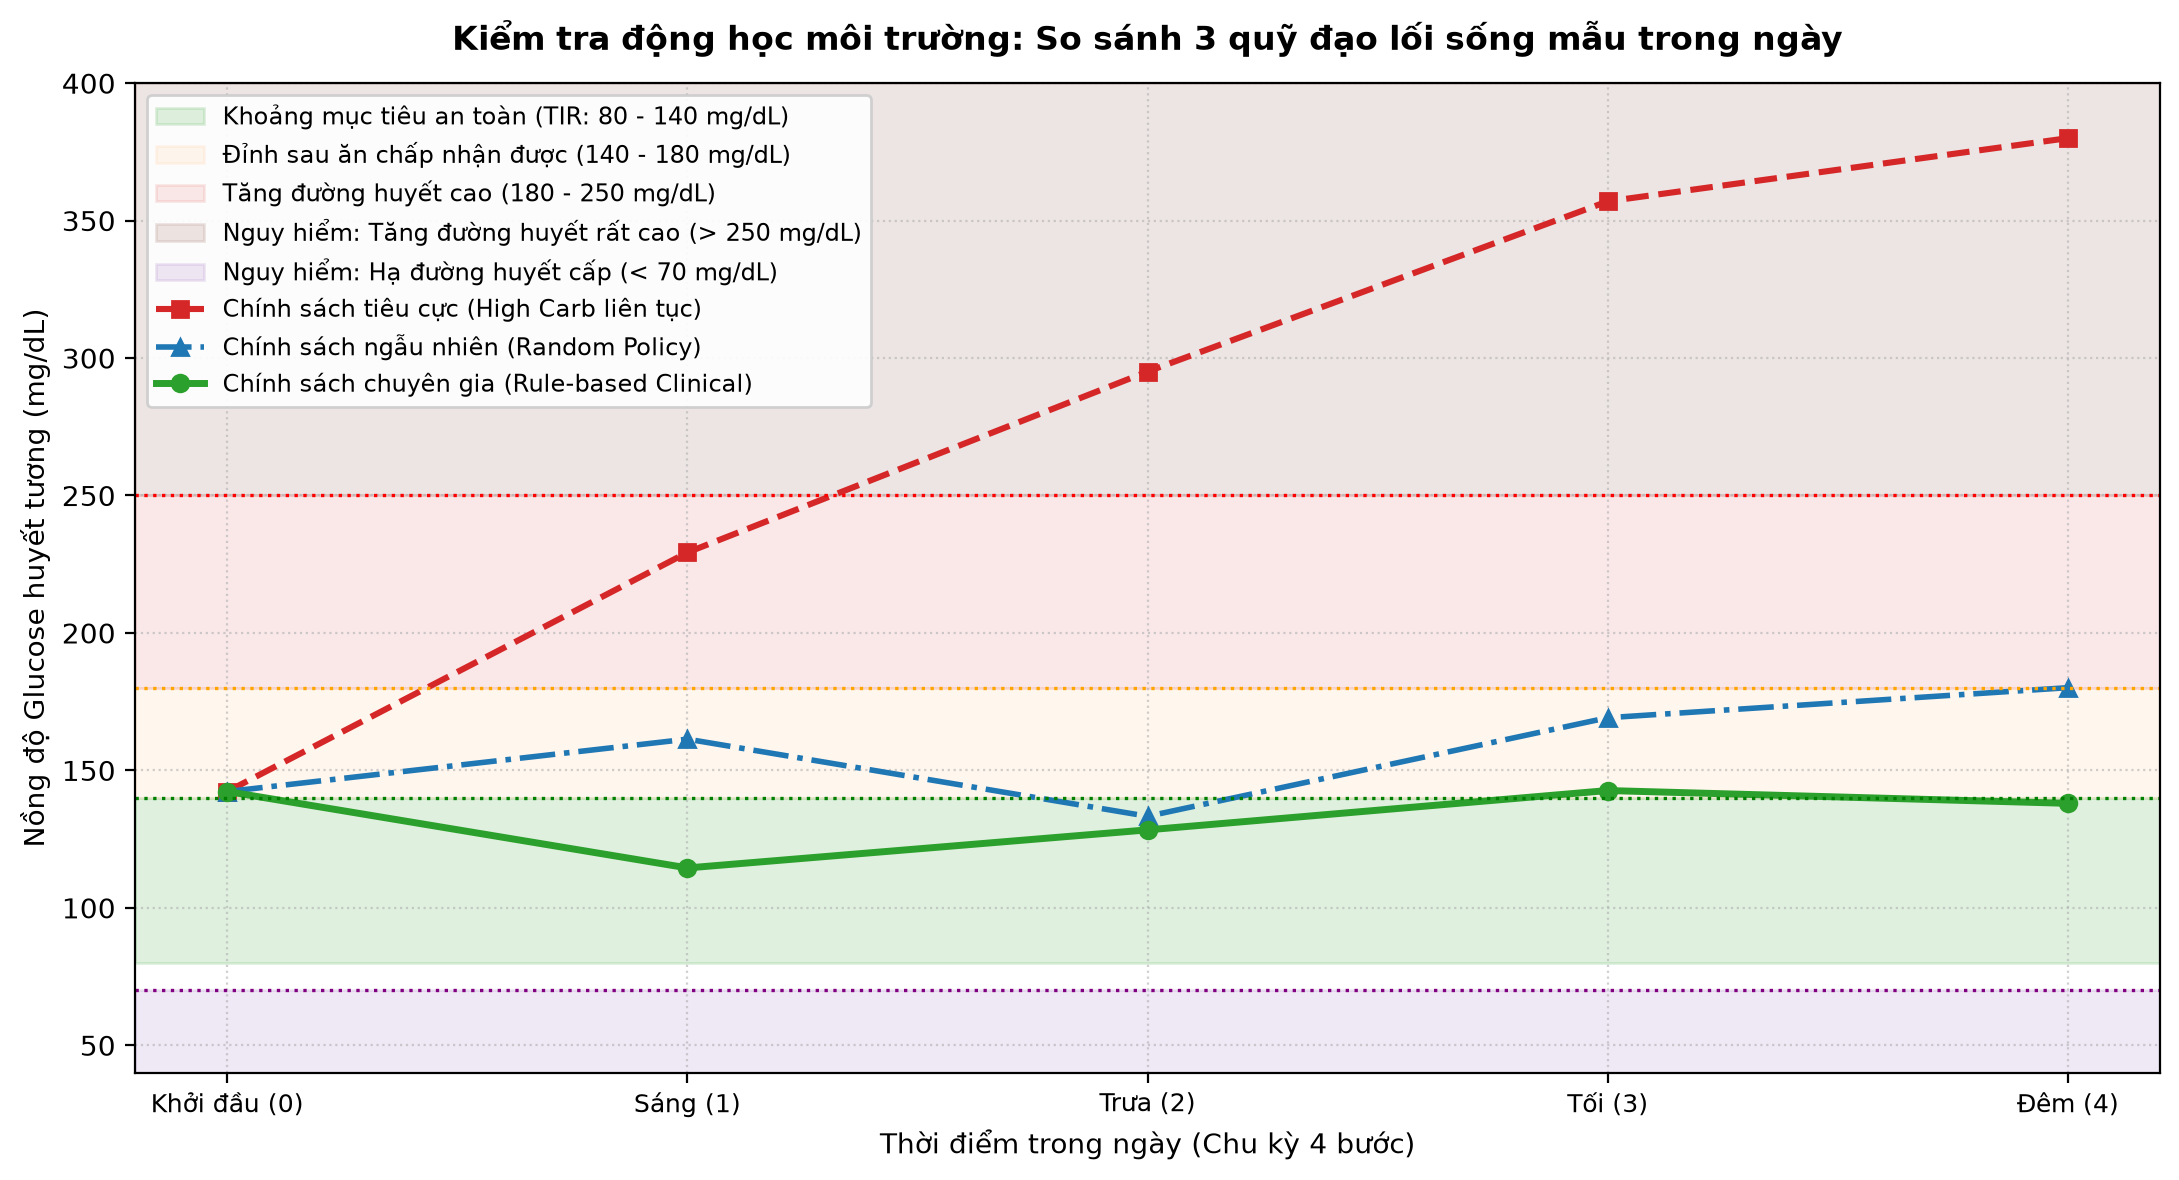

Đã lưu biểu đồ quỹ đạo môi trường: outputs/figures/f_nb03_sample_trajectories.png


In [10]:
# Cell 2.4: Trực quan hóa biến động đường huyết của 3 quỹ đạo lối sống mẫu
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(11, 6), dpi=200)

steps = [h["step"] for h in traj_random]
time_labels = ["Khởi đầu (0)", "Sáng (1)", "Trưa (2)", "Tối (3)", "Đêm (4)"]

# 1. Vẽ các dải màu phân vùng mục tiêu lâm sàng ADA / Bộ Y tế
ax.axhspan(80, 140, color="#2ca02c", alpha=0.15, label="Khoảng mục tiêu an toàn (TIR: 80 - 140 mg/dL)")
ax.axhspan(140, 180, color="#ffbb78", alpha=0.12, label="Đỉnh sau ăn chấp nhận được (140 - 180 mg/dL)")
ax.axhspan(180, 250, color="#d62728", alpha=0.10, label="Tăng đường huyết cao (180 - 250 mg/dL)")
ax.axhspan(250, 400, color="#8c564b", alpha=0.15, label="Nguy hiểm: Tăng đường huyết rất cao (> 250 mg/dL)")
ax.axhspan(40, 70, color="#9467bd", alpha=0.15, label="Nguy hiểm: Hạ đường huyết cấp (< 70 mg/dL)")

# 2. Vẽ 3 đường biểu diễn nồng độ glucose
g_bad = [h["glucose"] for h in traj_bad]
g_random = [h["glucose"] for h in traj_random]
g_rule = [h["glucose"] for h in traj_rule]

ax.plot(steps, g_bad, marker="s", color="#d62728", lw=2.2, linestyle="--", label="Chính sách tiêu cực (High Carb liên tục)")
ax.plot(steps, g_random, marker="^", color="#1f77b4", lw=2.0, linestyle="-.", label="Chính sách ngẫu nhiên (Random Policy)")
ax.plot(steps, g_rule, marker="o", color="#2ca02c", lw=2.5, linestyle="-", label="Chính sách chuyên gia (Rule-based Clinical)")

# 3. Kẻ các đường ranh giới ngưỡng lâm sàng quan trọng
ax.axhline(70, color="purple", linestyle=":", lw=1.2)
ax.axhline(140, color="green", linestyle=":", lw=1.2)
ax.axhline(180, color="orange", linestyle=":", lw=1.2)
ax.axhline(250, color="red", linestyle=":", lw=1.2)

ax.set_title("Kiểm tra động học môi trường: So sánh 3 quỹ đạo lối sống mẫu trong ngày", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Thời điểm trong ngày (Chu kỳ 4 bước)", fontsize=10)
ax.set_ylabel("Nồng độ Glucose huyết tương (mg/dL)", fontsize=10)
ax.set_xticks(steps)
ax.set_xticklabels(time_labels, fontsize=9)
ax.set_ylim(40, 400)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper left", fontsize=8.5, framealpha=0.9)

plt.tight_layout()
fig_traj_path = "outputs/figures/f_nb03_sample_trajectories.png"
plt.savefig(fig_traj_path, dpi=200)
plt.show()
print(f"Đã lưu biểu đồ quỹ đạo môi trường: {fig_traj_path}")

In [11]:
# Cell 2.5: Kiểm định thống kê Monte Carlo (100 Episodes) trên môi trường chưa huấn luyện
import json
import numpy as np
import pandas as pd

def run_monte_carlo_rollout(policy_type: str, num_episodes: int = 100, seed_base: int = 1000):
    """Chạy đánh giá Monte Carlo ngẫu nhiên 100 chu kỳ ngày."""
    mc_env = DiabetesLifestyleEnv(rules_dict=loaded_rules.get("safety_rules", {}))
    
    episode_rewards = []
    total_steps = 0
    in_range_steps = 0
    violation_steps = 0
    hypo_steps = 0
    hyper_steps = 0
    
    for ep in range(num_episodes):
        obs, _ = mc_env.reset(seed=seed_base + ep)
        ep_ret = 0.0
        
        for t in range(4):
            g = float(obs[0])
            s_idx = int(obs[1])
            
            if policy_type == "random":
                act_id = mc_env.rng.integers(0, mc_env.action_space.n)
            elif policy_type == "maladaptive":
                act_id = 8
            elif policy_type == "rule_based":
                act_id = rule_based_clinical_policy(g, s_idx, mc_env)
            else:
                act_id = 0
                
            obs, r, term, trunc, info = mc_env.step(act_id)
            ep_ret += r
            total_steps += 1
            
            if info["in_target_range"]:
                in_range_steps += 1
            if len(info["violations"]) > 0:
                violation_steps += 1
            if info["next_glucose"] < 70.0:
                hypo_steps += 1
            if info["next_glucose"] > 250.0:
                hyper_steps += 1
                
            if term:
                break
                
        episode_rewards.append(ep_ret)
        
    return {
        "policy_name": policy_type,
        "mean_episode_reward": round(float(np.mean(episode_rewards)), 2),
        "std_episode_reward": round(float(np.std(episode_rewards)), 2),
        "time_in_range_ratio": round(float(in_range_steps / total_steps), 4),
        "rule_violation_rate": round(float(violation_steps / total_steps), 4),
        "hypo_event_rate": round(float(hypo_steps / total_steps), 4),
        "severe_hyper_event_rate": round(float(hyper_steps / total_steps), 4)
    }

# Đo lường cho cả 3 chính sách
mc_results = [
    run_monte_carlo_rollout("random", num_episodes=100),
    run_monte_carlo_rollout("maladaptive", num_episodes=100),
    run_monte_carlo_rollout("rule_based", num_episodes=100)
]

df_mc = pd.DataFrame(mc_results)
print("=== KẾT QUẢ ĐÁNH GIÁ THỐNG KÊ MONTE CARLO (100 EPISODES) ===")
display(df_mc[["policy_name", "mean_episode_reward", "std_episode_reward", "time_in_range_ratio", "rule_violation_rate", "severe_hyper_event_rate"]])

# Lưu kết quả kiểm định vào file JSON
sanity_json_path = "outputs/metrics/env_sanity_check.json"
with open(sanity_json_path, "w", encoding="utf-8") as f:
    json.dump(mc_results, f, indent=4, ensure_ascii=False)
print(f"\nĐã lưu kết quả kiểm định môi trường vào: {sanity_json_path}")

=== KẾT QUẢ ĐÁNH GIÁ THỐNG KÊ MONTE CARLO (100 EPISODES) ===


,policy_name,mean_episode_reward,std_episode_reward,time_in_range_ratio,rule_violation_rate,severe_hyper_event_rate
0,random,-52.05,65.66,0.1550,0.1725,0.1500
1,maladaptive,-208.25,16.69,0.0000,0.7375,0.7525
2,rule_based,28.66,5.49,0.7325,0.0000,0.0000



Đã lưu kết quả kiểm định môi trường vào: outputs/metrics/env_sanity_check.json


In [12]:
# Cell 3.1: Hàm huấn luyện Tabular Q-Learning với cơ chế Epsilon-Greedy Decay
import numpy as np

def train_single_seed_q_learning(
    seed: int,
    num_episodes: int = 1500,
    alpha: float = 0.08,
    gamma: float = 0.95,
    eps_start: float = 1.0,
    eps_min: float = 0.02,
    eps_decay: float = 0.996
):
    """
    Huấn luyện Tabular Q-Learning trên môi trường DiabetesLifestyleEnv.
    - Cập nhật Bellman: Q(s, a) <- Q(s, a) + alpha * [r + gamma * max_a' Q(s', a') - Q(s, a)]
    - Hành vi thăm dò: Epsilon suy giảm từ 1.0 về 0.02 theo cấp số nhân
    """
    # Khởi tạo môi trường và bộ sinh số ngẫu nhiên theo seed
    train_env = DiabetesLifestyleEnv(rules_dict=loaded_rules.get("safety_rules", {}))
    rng = np.random.default_rng(seed)
    
    # Bảng Q-Table: 24 trạng thái x 12 hành động, khởi tạo bằng 0.0
    num_states = 24
    num_actions = 12
    Q_table = np.zeros((num_states, num_actions), dtype=np.float32)
    
    # Nhật ký theo dõi quá trình học tập
    history_rewards = []
    history_violations = []
    history_tir = []
    history_epsilons = []
    
    current_eps = eps_start
    
    for ep in range(num_episodes):
        # Khởi tạo chu kỳ ngày với seed con độc lập
        obs, _ = train_env.reset(seed=int(rng.integers(0, 1_000_000)))
        state = discretize_state(obs[0], int(obs[1]))
        
        ep_reward = 0.0
        ep_violations = 0
        ep_in_range_steps = 0
        
        for t in range(4):
            # Chọn hành động theo chính sách Epsilon-Greedy
            if rng.uniform(0.0, 1.0) < current_eps:
                action = int(rng.integers(0, num_actions))
            else:
                # Phá vỡ hòa điểm ngẫu nhiên nếu có nhiều hành động cùng giá trị Q cực đại
                q_values = Q_table[state, :]
                max_q = np.max(q_values)
                best_actions = np.where(q_values == max_q)[0]
                action = int(rng.choice(best_actions))
                
            next_obs, reward, terminated, truncated, info = train_env.step(action)
            next_state = discretize_state(next_obs[0], int(next_obs[1]))
            
            # Cập nhật giá trị Q-value theo công thức Tabular Q-Learning
            q_target = reward + (0.0 if terminated else gamma * np.max(Q_table[next_state, :]))
            Q_table[state, action] = Q_table[state, action] + alpha * (q_target - Q_table[state, action])
            
            # Chuyển trạng thái
            state = next_state
            ep_reward += reward
            
            if len(info["violations"]) > 0:
                ep_violations += len(info["violations"])
            if info["in_target_range"]:
                ep_in_range_steps += 1
                
            if terminated:
                break
                
        # Suy giảm Epsilon sau mỗi chu kỳ ngày
        current_eps = max(eps_min, current_eps * eps_decay)
        
        history_rewards.append(ep_reward)
        history_violations.append(ep_violations)
        history_tir.append(ep_in_range_steps / 4.0)
        history_epsilons.append(current_eps)
        
    return {
        "seed": seed,
        "Q_table": Q_table,
        "rewards": np.array(history_rewards, dtype=np.float32),
        "violations": np.array(history_violations, dtype=np.float32),
        "tir": np.array(history_tir, dtype=np.float32),
        "epsilons": np.array(history_epsilons, dtype=np.float32)
    }

print("Đã định nghĩa thành công hàm train_single_seed_q_learning().")

Đã định nghĩa thành công hàm train_single_seed_q_learning().


In [13]:
# Cell 3.2: Huấn luyện Q-Learning trên 5 Random Seed độc lập
import time

SEEDS_LIST = [42, 101, 2024, 777, 9999]
NUM_EPISODES = 1500

q_training_runs = {}
start_total_time = time.time()

print(f"=== BẮT ĐẦU HUẤN LUYỆN Q-LEARNING TRÊN {len(SEEDS_LIST)} RANDOM SEEDS ===")
for s in SEEDS_LIST:
    t_start = time.time()
    run_result = train_single_seed_q_learning(
        seed=s,
        num_episodes=NUM_EPISODES,
        alpha=0.08,
        gamma=0.95,
        eps_start=1.0,
        eps_min=0.02,
        eps_decay=0.996
    )
    t_duration = time.time() - t_start
    q_training_runs[s] = run_result
    
    # Tính toán hiệu năng trung bình 100 tập cuối của seed hiện tại
    final_100_rew = np.mean(run_result["rewards"][-100:])
    final_100_tir = np.mean(run_result["tir"][-100:]) * 100.0
    final_100_viols = np.mean(run_result["violations"][-100:])
    
    print(f">> Hoàn tất Seed {s:04d} ({t_duration:.2f}s) | 100 tập cuối: Reward = {final_100_rew:.2f} | TIR = {final_100_tir:.1f}% | Lỗi luật = {final_100_viols:.3f}")

total_elapsed = time.time() - start_total_time
print(f"\nTổng thời gian hoàn tất toàn bộ 5 seeds: {total_elapsed:.2f} giây.")

=== BẮT ĐẦU HUẤN LUYỆN Q-LEARNING TRÊN 5 RANDOM SEEDS ===
>> Hoàn tất Seed 0042 (0.36s) | 100 tập cuối: Reward = 33.31 | TIR = 87.2% | Lỗi luật = 0.000
>> Hoàn tất Seed 0101 (0.33s) | 100 tập cuối: Reward = 30.09 | TIR = 87.2% | Lỗi luật = 0.020
>> Hoàn tất Seed 2024 (0.33s) | 100 tập cuối: Reward = 30.90 | TIR = 84.2% | Lỗi luật = 0.000
>> Hoàn tất Seed 0777 (0.34s) | 100 tập cuối: Reward = 32.39 | TIR = 86.8% | Lỗi luật = 0.000
>> Hoàn tất Seed 9999 (0.34s) | 100 tập cuối: Reward = 33.58 | TIR = 90.0% | Lỗi luật = 0.010

Tổng thời gian hoàn tất toàn bộ 5 seeds: 1.70 giây.


In [14]:
# Cell 3.3: Tổng hợp thống kê tiến trình học tập qua 5 seeds (Rolling Mean & Std)
import json
import os
import numpy as np

# 1. Tạo ma trận phần thưởng, vi phạm luật và TIR có kích thước (5, 1500)
reward_matrix = np.array([q_training_runs[s]["rewards"] for s in SEEDS_LIST])
violation_matrix = np.array([q_training_runs[s]["violations"] for s in SEEDS_LIST])
tir_matrix = np.array([q_training_runs[s]["tir"] for s in SEEDS_LIST])

# 2. Hàm làm mượt bằng cửa sổ trượt 50 tập để khử nhiễu ngẫu nhiên
def compute_rolling_trajectory(matrix: np.ndarray, window: int = 50):
    smoothed_matrix = np.zeros_like(matrix)
    for row_idx in range(matrix.shape[0]):
        cumsum = np.cumsum(np.insert(matrix[row_idx], 0, 0))
        valid_means = (cumsum[window:] - cumsum[:-window]) / float(window)
        head_means = np.array([np.mean(matrix[row_idx, :max(1, j+1)]) for j in range(window - 1)])
        smoothed_matrix[row_idx] = np.concatenate([head_means, valid_means])
    return smoothed_matrix

smooth_rewards = compute_rolling_trajectory(reward_matrix, window=50)
mean_reward_curve = np.mean(smooth_rewards, axis=0)
std_reward_curve = np.std(smooth_rewards, axis=0)

smooth_tir = compute_rolling_trajectory(tir_matrix, window=50)
mean_tir_curve = np.mean(smooth_tir, axis=0)
std_tir_curve = np.std(smooth_tir, axis=0)

smooth_viols = compute_rolling_trajectory(violation_matrix, window=50)
mean_viols_curve = np.mean(smooth_viols, axis=0)
std_viols_curve = np.std(smooth_viols, axis=0)

# 3. Tổng hợp số liệu định lượng vào file JSON
os.makedirs("outputs/metrics", exist_ok=True)
training_summary_payload = {
    "project": "NB03 Reinforcement Learning - Training Progress",
    "evaluated_seeds": SEEDS_LIST,
    "total_episodes_per_seed": NUM_EPISODES,
    "smoothing_window_size": 50,
    "metrics_stage_progression": {
        "initial_100_episodes": {
            "mean_reward": round(float(np.mean(reward_matrix[:, :100])), 2),
            "std_reward": round(float(np.std(reward_matrix[:, :100])), 2),
            "mean_tir_percent": round(float(np.mean(tir_matrix[:, :100]) * 100), 2),
            "mean_violations_per_episode": round(float(np.mean(violation_matrix[:, :100])), 2)
        },
        "final_100_episodes": {
            "mean_reward": round(float(np.mean(reward_matrix[:, -100:])), 2),
            "std_reward": round(float(np.std(reward_matrix[:, -100:])), 2),
            "mean_tir_percent": round(float(np.mean(tir_matrix[:, -100:]) * 100), 2),
            "std_tir_percent": round(float(np.std(tir_matrix[:, -100:]) * 100), 2),
            "mean_violations_per_episode": round(float(np.mean(violation_matrix[:, -100:])), 4)
        }
    }
}

progress_json_path = "outputs/metrics/q_learning_training_progress.json"
with open(progress_json_path, "w", encoding="utf-8") as f:
    json.dump(training_summary_payload, f, indent=4, ensure_ascii=False)

print(f"=== ĐÃ TỔNG HỢP VÀ LƯU TIẾN TRÌNH HUẤN LUYỆN VÀO: {progress_json_path} ===")
print(f"- Reward 100 tập đầu: {training_summary_payload['metrics_stage_progression']['initial_100_episodes']['mean_reward']:.2f}")
print(f"- Reward 100 tập cuối: {training_summary_payload['metrics_stage_progression']['final_100_episodes']['mean_reward']:.2f} ± {training_summary_payload['metrics_stage_progression']['final_100_episodes']['std_reward']:.2f}")
print(f"- TIR 100 tập cuối   : {training_summary_payload['metrics_stage_progression']['final_100_episodes']['mean_tir_percent']:.1f}%")

=== ĐÃ TỔNG HỢP VÀ LƯU TIẾN TRÌNH HUẤN LUYỆN VÀO: outputs/metrics/q_learning_training_progress.json ===
- Reward 100 tập đầu: -38.98
- Reward 100 tập cuối: 32.06 ± 7.26
- TIR 100 tập cuối   : 87.1%


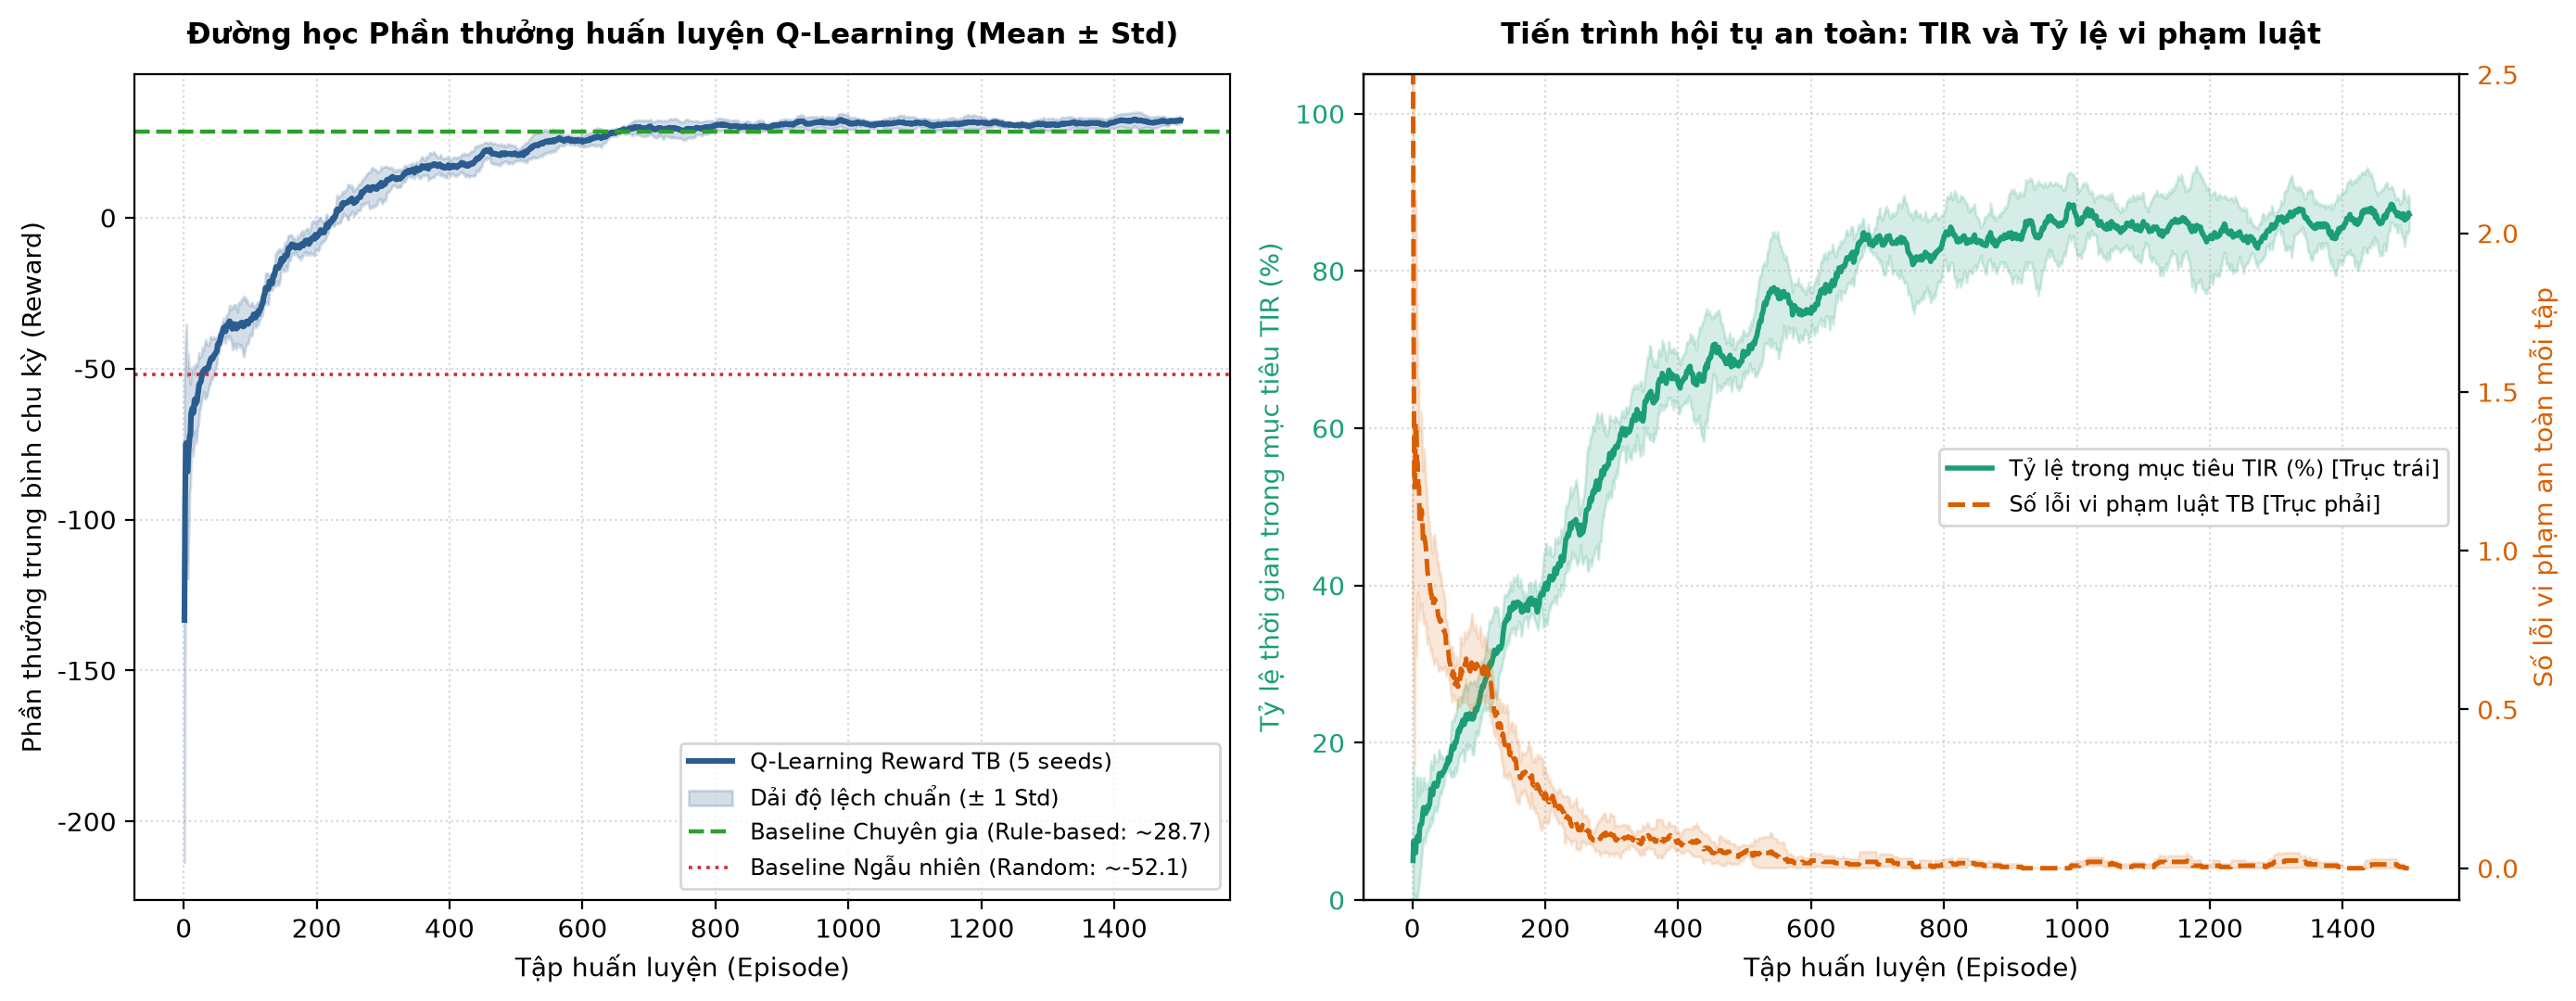

Đã lưu biểu đồ đường học: outputs/figures/f_nb03_learning_curves.png


In [15]:
# Cell 3.4: Trực quan hóa đường học trung bình kèm độ lệch chuẩn (f_nb03_learning_curves.png)
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

os.makedirs("outputs/figures", exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=200)
episodes_axis = np.arange(1, NUM_EPISODES + 1)

# --- ĐỒ THỊ 1: ĐƯỜNG CONG PHẦN THƯỞNG TÍCH LŨY (REWARD LEARNING CURVE) ---
axes[0].plot(episodes_axis, mean_reward_curve, color="#2b5c8f", lw=2.2, label="Q-Learning Reward TB (5 seeds)")
axes[0].fill_between(
    episodes_axis,
    mean_reward_curve - std_reward_curve,
    mean_reward_curve + std_reward_curve,
    color="#2b5c8f",
    alpha=0.20,
    label="Dải độ lệch chuẩn (± 1 Std)"
)
# Các đường đối chuẩn chuẩn mực
axes[0].axhline(y=28.66, color="#2ca02c", linestyle="--", lw=1.6, label="Baseline Chuyên gia (Rule-based: ~28.7)")
axes[0].axhline(y=-52.05, color="#d62728", linestyle=":", lw=1.3, label="Baseline Ngẫu nhiên (Random: ~-52.1)")

axes[0].set_title("Đường học Phần thưởng huấn luyện Q-Learning (Mean ± Std)", fontsize=11, fontweight="bold", pad=12)
axes[0].set_xlabel("Tập huấn luyện (Episode)", fontsize=10)
axes[0].set_ylabel("Phần thưởng trung bình chu kỳ (Reward)", fontsize=10)
axes[0].grid(True, linestyle=":", alpha=0.5)
axes[0].legend(loc="lower right", fontsize=8.5)

# --- ĐỒ THỊ 2: TIẾN TRÌNH HỘI TỤ AN TOÀN (TIR VÀ LỖI LUẬT AN TOÀN) ---
ax_tir = axes[1]
ax_tir.plot(episodes_axis, mean_tir_curve * 100.0, color="#1b9e77", lw=2.0, label="Tỷ lệ trong mục tiêu TIR (%) [Trục trái]")
ax_tir.fill_between(
    episodes_axis,
    (mean_tir_curve - std_tir_curve) * 100.0,
    (mean_tir_curve + std_tir_curve) * 100.0,
    color="#1b9e77",
    alpha=0.18
)
ax_tir.set_xlabel("Tập huấn luyện (Episode)", fontsize=10)
ax_tir.set_ylabel("Tỷ lệ thời gian trong mục tiêu TIR (%)", color="#1b9e77", fontsize=10)
ax_tir.tick_params(axis="y", labelcolor="#1b9e77")
ax_tir.set_ylim(0, 105)
ax_tir.grid(True, linestyle=":", alpha=0.5)

# Trục kép y thứ hai dành cho số lỗi vi phạm an toàn
ax_viols = ax_tir.twinx()
ax_viols.plot(episodes_axis, mean_viols_curve, color="#d95f02", lw=1.8, linestyle="--", label="Số lỗi vi phạm luật TB [Trục phải]")
ax_viols.fill_between(
    episodes_axis,
    np.maximum(0, mean_viols_curve - std_viols_curve),
    mean_viols_curve + std_viols_curve,
    color="#d95f02",
    alpha=0.15
)
ax_viols.set_ylabel("Số lỗi vi phạm an toàn mỗi tập", color="#d95f02", fontsize=10)
ax_viols.tick_params(axis="y", labelcolor="#d95f02")
ax_viols.set_ylim(-0.1, 2.5)

ax_tir.set_title("Tiến trình hội tụ an toàn: TIR và Tỷ lệ vi phạm luật", fontsize=11, fontweight="bold", pad=12)

# Ghép nhãn chú thích cho cả hai trục
lines_tir, labels_tir = ax_tir.get_legend_handles_labels()
lines_v, labels_v = ax_viols.get_legend_handles_labels()
ax_tir.legend(lines_tir + lines_v, labels_tir + labels_v, loc="center right", fontsize=8.5)

plt.tight_layout()
fig_learning_path = "outputs/figures/f_nb03_learning_curves.png"
plt.savefig(fig_learning_path, dpi=200)
plt.show()
print(f"Đã lưu biểu đồ đường học: {fig_learning_path}")

In [16]:
# Cell 3.5: Xác định Seed tối ưu và lưu Checkpoint Q-Table (best_q_table_seed.npy)
import os
import numpy as np

# 1. Tìm seed đạt phần thưởng trung bình 100 tập cuối cao nhất
best_seed = None
best_final_reward = -999999.0

for s in SEEDS_LIST:
    seed_final_rew = float(np.mean(q_training_runs[s]["rewards"][-100:]))
    if seed_final_rew > best_final_reward:
        best_final_reward = seed_final_rew
        best_seed = s

best_q_table = q_training_runs[best_seed]["Q_table"]

# 2. Lưu bảng Q-Table tốt nhất vào thư mục outputs/models/
os.makedirs("outputs/models", exist_ok=True)
best_q_path = "outputs/models/best_q_table_seed.npy"
np.save(best_q_path, best_q_table)

print("=== CHECKPOINT Q-TABLE HUẤN LUYỆN ĐÃ ĐƯỢC LƯU TRỮ THÀNH CÔNG ===")
print(f"- Seed chiến thắng   : Seed {best_seed}")
print(f"- Reward 100 tập cuối : {best_final_reward:.2f}")
print(f"- Kích thước Q-Table  : {best_q_table.shape} (24 trạng thái x 12 hành động)")
print(f"- Tệp lưu trữ         : {best_q_path} ({os.path.getsize(best_q_path) / 1024:.2f} KB)")

=== CHECKPOINT Q-TABLE HUẤN LUYỆN ĐÃ ĐƯỢC LƯU TRỮ THÀNH CÔNG ===
- Seed chiến thắng   : Seed 9999
- Reward 100 tập cuối : 33.58
- Kích thước Q-Table  : (24, 12) (24 trạng thái x 12 hành động)
- Tệp lưu trữ         : outputs/models/best_q_table_seed.npy (1.25 KB)


In [17]:
# Cell 4.1: Nạp Checkpoint Q-Table tối ưu và định nghĩa chính sách suy luận Greedy
import os
import numpy as np

# 1. Tái nạp Q-table tốt nhất đã lưu từ Chặng 3
checkpoint_path = "outputs/models/best_q_table_seed.npy"
if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(f"Không tìm thấy checkpoint {checkpoint_path}. Hãy chạy xong Chặng 3!")

trained_Q_table = np.load(checkpoint_path)
print("=== THÔNG TIN CHECKPOINT Q-TABLE ĐÃ NẠP ===")
print(f"- Đường dẫn tệp : {checkpoint_path}")
print(f"- Kích thước    : {trained_Q_table.shape} (24 trạng thái x 12 hành động)")
print(f"- Giá trị Q min : {np.min(trained_Q_table):.2f} | max: {np.max(trained_Q_table):.2f}")

# 2. Định nghĩa hàm suy luận thuần túy khai thác cho tác tử Q-learning
def trained_q_learning_policy(glucose: float, step_idx: int, env) -> int:
    """Chính sách khai thác tối đa (Greedy Policy, epsilon = 0.0): a* = argmax_a Q(s, a)."""
    state_id = discretize_state(glucose, step_idx)
    q_vals = trained_Q_table[state_id, :]
    max_q = np.max(q_vals)
    best_actions = np.where(q_vals == max_q)[0]
    return int(best_actions[0])

print("Đã sẵn sàng chính sách suy luận thuần túy khai thác (Greedy Policy).")

=== THÔNG TIN CHECKPOINT Q-TABLE ĐÃ NẠP ===
- Đường dẫn tệp : outputs/models/best_q_table_seed.npy
- Kích thước    : (24, 12) (24 trạng thái x 12 hành động)
- Giá trị Q min : -28.47 | max: 31.15
Đã sẵn sàng chính sách suy luận thuần túy khai thác (Greedy Policy).


In [18]:
# Cell 4.2: Thiết lập tập 200 tình huống kiểm thử cố định (Fixed Evaluation Scenarios)
NUM_EVAL_EPISODES = 200
EVAL_SEED_START = 10000

# Tạo danh sách 200 hạt giống ngẫu nhiên độc lập cố định cho tập kiểm thử
fixed_eval_seeds = [EVAL_SEED_START + i for i in range(NUM_EVAL_EPISODES)]

# Khởi tạo trước một chuỗi các mức đường huyết ban đầu để kiểm tra phân bố tình huống
eval_env = DiabetesLifestyleEnv(rules_dict=loaded_rules.get("safety_rules", {}))
sample_initial_glucoses = []
for s in fixed_eval_seeds:
    obs, _ = eval_env.reset(seed=s)
    sample_initial_glucoses.append(obs[0])

print(f"=== ĐÃ KHỞI TẠO TẬP KIỂM THỬ CỐ ĐỊNH: {NUM_EVAL_EPISODES} CHU KỲ NGÀY ===")
print(f"- Dải seed sử dụng       : Từ {fixed_eval_seeds[0]} đến {fixed_eval_seeds[-1]}")
print(f"- Đường huyết đầu ngày TB: {np.mean(sample_initial_glucoses):.2f} mg/dL (Min: {np.min(sample_initial_glucoses):.2f}, Max: {np.max(sample_initial_glucoses):.2f})")
print(f"- Tỷ lệ phân bổ ban đầu  : Bao phủ đa dạng từ bệnh nhân cận bình thường đến tăng đường huyết")

=== ĐÃ KHỞI TẠO TẬP KIỂM THỬ CỐ ĐỊNH: 200 CHU KỲ NGÀY ===
- Dải seed sử dụng       : Từ 10000 đến 10199
- Đường huyết đầu ngày TB: 128.28 mg/dL (Min: 95.06, Max: 164.98)
- Tỷ lệ phân bổ ban đầu  : Bao phủ đa dạng từ bệnh nhân cận bình thường đến tăng đường huyết


In [19]:
# Cell 4.3: Thực thi đánh giá đối chuẩn 3 chính sách trên tập tình huống cố định
def evaluate_agent_on_fixed_scenarios(policy_func, policy_label: str):
    """Đánh giá một chính sách trên 200 tập tình huống kiểm thử cố định."""
    test_env = DiabetesLifestyleEnv(rules_dict=loaded_rules.get("safety_rules", {}))
    
    episode_returns = []
    total_steps = 0
    in_range_steps = 0
    violation_steps = 0
    hypo_steps = 0
    severe_hyper_steps = 0
    
    for s in fixed_eval_seeds:
        obs, _ = test_env.reset(seed=s)
        ep_reward = 0.0
        
        for t in range(4):
            g = float(obs[0])
            s_idx = int(obs[1])
            
            action_id = policy_func(g, s_idx, test_env)
            obs, r, term, trunc, info = test_env.step(action_id)
            
            ep_reward += r
            total_steps += 1
            
            if info["in_target_range"]:
                in_range_steps += 1
            if len(info["violations"]) > 0:
                violation_steps += 1
            if info["next_glucose"] < 70.0:
                hypo_steps += 1
            if info["next_glucose"] > 250.0:
                severe_hyper_steps += 1
                
            if term:
                break
                
        episode_returns.append(ep_reward)
        
    return {
        "policy_name": policy_label,
        "mean_episode_reward": round(float(np.mean(episode_returns)), 2),
        "std_episode_reward": round(float(np.std(episode_returns)), 2),
        "median_episode_reward": round(float(np.median(episode_returns)), 2),
        "time_in_range_ratio": round(float(in_range_steps / total_steps), 4),
        "time_in_range_percent": round(float(in_range_steps / total_steps * 100.0), 2),
        "rule_violation_rate": round(float(violation_steps / total_steps), 4),
        "rule_violation_percent": round(float(violation_steps / total_steps * 100.0), 2),
        "hypo_event_rate": round(float(hypo_steps / total_steps), 4),
        "severe_hyper_event_rate": round(float(severe_hyper_steps / total_steps), 4),
        "episode_returns_raw": episode_returns
    }

# 1. Đánh giá Baseline 1: Chính sách Ngẫu nhiên
eval_random = evaluate_agent_on_fixed_scenarios(
    lambda g, s, env: env.rng.integers(0, env.action_space.n),
    "Chính sách Ngẫu nhiên (Random Baseline)"
)

# 2. Đánh giá Baseline 2: Chuyên gia Luật y khoa tiền định
eval_rule_based = evaluate_agent_on_fixed_scenarios(
    rule_based_clinical_policy,
    "Chuyên gia Luật (Rule-Based Baseline)"
)

# 3. Đánh giá Mô hình đề xuất: Tác tử Q-Learning đã huấn luyện
eval_q_learning = evaluate_agent_on_fixed_scenarios(
    trained_q_learning_policy,
    "Học tăng cường (Trained Q-Learning)"
)

print("Đã hoàn tất đánh giá đối chuẩn 3 chính sách trên 200 tập tình huống cố định.")

Đã hoàn tất đánh giá đối chuẩn 3 chính sách trên 200 tập tình huống cố định.


In [20]:
# Cell 4.4: Bảng tổng kết đối chuẩn định lượng và lưu kết quả JSON
import json
import os
import pandas as pd

# 1. Tổng hợp dữ liệu thành bảng đối chuẩn so sánh
benchmark_summary_rows = [
    {
        "Chính sách đề xuất lối sống": eval_random["policy_name"],
        "Reward chu kỳ (Mean ± Std)": f"{eval_random['mean_episode_reward']:.2f} ± {eval_random['std_episode_reward']:.2f}",
        "Reward trung vị": eval_random["median_episode_reward"],
        "TIR Trong mục tiêu (%)": f"{eval_random['time_in_range_percent']:.2f}%",
        "Tỷ lệ vi phạm luật (%)": f"{eval_random['rule_violation_percent']:.2f}%",
        "Tỷ lệ hạ ĐH (<70 mg/dL)": f"{eval_random['hypo_event_rate'] * 100:.2f}%",
        "Tăng ĐH nặng (>250 mg/dL)": f"{eval_random['severe_hyper_event_rate'] * 100:.2f}%"
    },
    {
        "Chính sách đề xuất lối sống": eval_rule_based["policy_name"],
        "Reward chu kỳ (Mean ± Std)": f"{eval_rule_based['mean_episode_reward']:.2f} ± {eval_rule_based['std_episode_reward']:.2f}",
        "Reward trung vị": eval_rule_based["median_episode_reward"],
        "TIR Trong mục tiêu (%)": f"{eval_rule_based['time_in_range_percent']:.2f}%",
        "Tỷ lệ vi phạm luật (%)": f"{eval_rule_based['rule_violation_percent']:.2f}%",
        "Tỷ lệ hạ ĐH (<70 mg/dL)": f"{eval_rule_based['hypo_event_rate'] * 100:.2f}%",
        "Tăng ĐH nặng (>250 mg/dL)": f"{eval_rule_based['severe_hyper_event_rate'] * 100:.2f}%"
    },
    {
        "Chính sách đề xuất lối sống": eval_q_learning["policy_name"],
        "Reward chu kỳ (Mean ± Std)": f"{eval_q_learning['mean_episode_reward']:.2f} ± {eval_q_learning['std_episode_reward']:.2f}",
        "Reward trung vị": eval_q_learning["median_episode_reward"],
        "TIR Trong mục tiêu (%)": f"{eval_q_learning['time_in_range_percent']:.2f}%",
        "Tỷ lệ vi phạm luật (%)": f"{eval_q_learning['rule_violation_percent']:.2f}%",
        "Tỷ lệ hạ ĐH (<70 mg/dL)": f"{eval_q_learning['hypo_event_rate'] * 100:.2f}%",
        "Tăng ĐH nặng (>250 mg/dL)": f"{eval_q_learning['severe_hyper_event_rate'] * 100:.2f}%"
    }
]

df_benchmark = pd.DataFrame(benchmark_summary_rows)
print("=== BẢNG ĐỐI CHUẨN HIỆU NĂNG 3 TÁC TỬ TRÊN 200 TÌNH HUỐNG KIỂM THỬ ===")
display(df_benchmark)

# 2. Lưu kết quả ra file JSON
os.makedirs("outputs/metrics", exist_ok=True)
benchmark_json_path = "outputs/metrics/rl_benchmark_evaluation.json"

benchmark_payload = {
    "evaluation_protocol": "200 Fixed Test Scenarios (Seeds 10000 - 10199)",
    "summary_table": benchmark_summary_rows,
    "detailed_metrics": {
        "random_baseline": {k: v for k, v in eval_random.items() if k != "episode_returns_raw"},
        "rule_based_baseline": {k: v for k, v in eval_rule_based.items() if k != "episode_returns_raw"},
        "trained_q_learning": {k: v for k, v in eval_q_learning.items() if k != "episode_returns_raw"}
    }
}

with open(benchmark_json_path, "w", encoding="utf-8") as f:
    json.dump(benchmark_payload, f, indent=4, ensure_ascii=False)
print(f"\nĐã lưu kết quả đối chuẩn vào: {benchmark_json_path}")

=== BẢNG ĐỐI CHUẨN HIỆU NĂNG 3 TÁC TỬ TRÊN 200 TÌNH HUỐNG KIỂM THỬ ===


,Chính sách đề xuất lối sống,Reward chu kỳ (Mean ± Std),Reward trung vị,TIR Trong mục tiêu (%),Tỷ lệ vi phạm luật (%),Tỷ lệ hạ ĐH (<70 mg/dL),Tăng ĐH nặng (>250 mg/dL)
0,Chính sách Ngẫu nhiên (Random Baseline),-47.34 ± 61.02,-28.78,15.75%,17.12%,0.00%,14.12%
1,Chuyên gia Luật (Rule-Based Baseline),28.20 ± 5.43,28.73,71.38%,0.00%,0.00%,0.00%
2,Học tăng cường (Trained Q-Learning),34.63 ± 5.01,37.36,90.75%,0.00%,0.00%,0.00%



Đã lưu kết quả đối chuẩn vào: outputs/metrics/rl_benchmark_evaluation.json


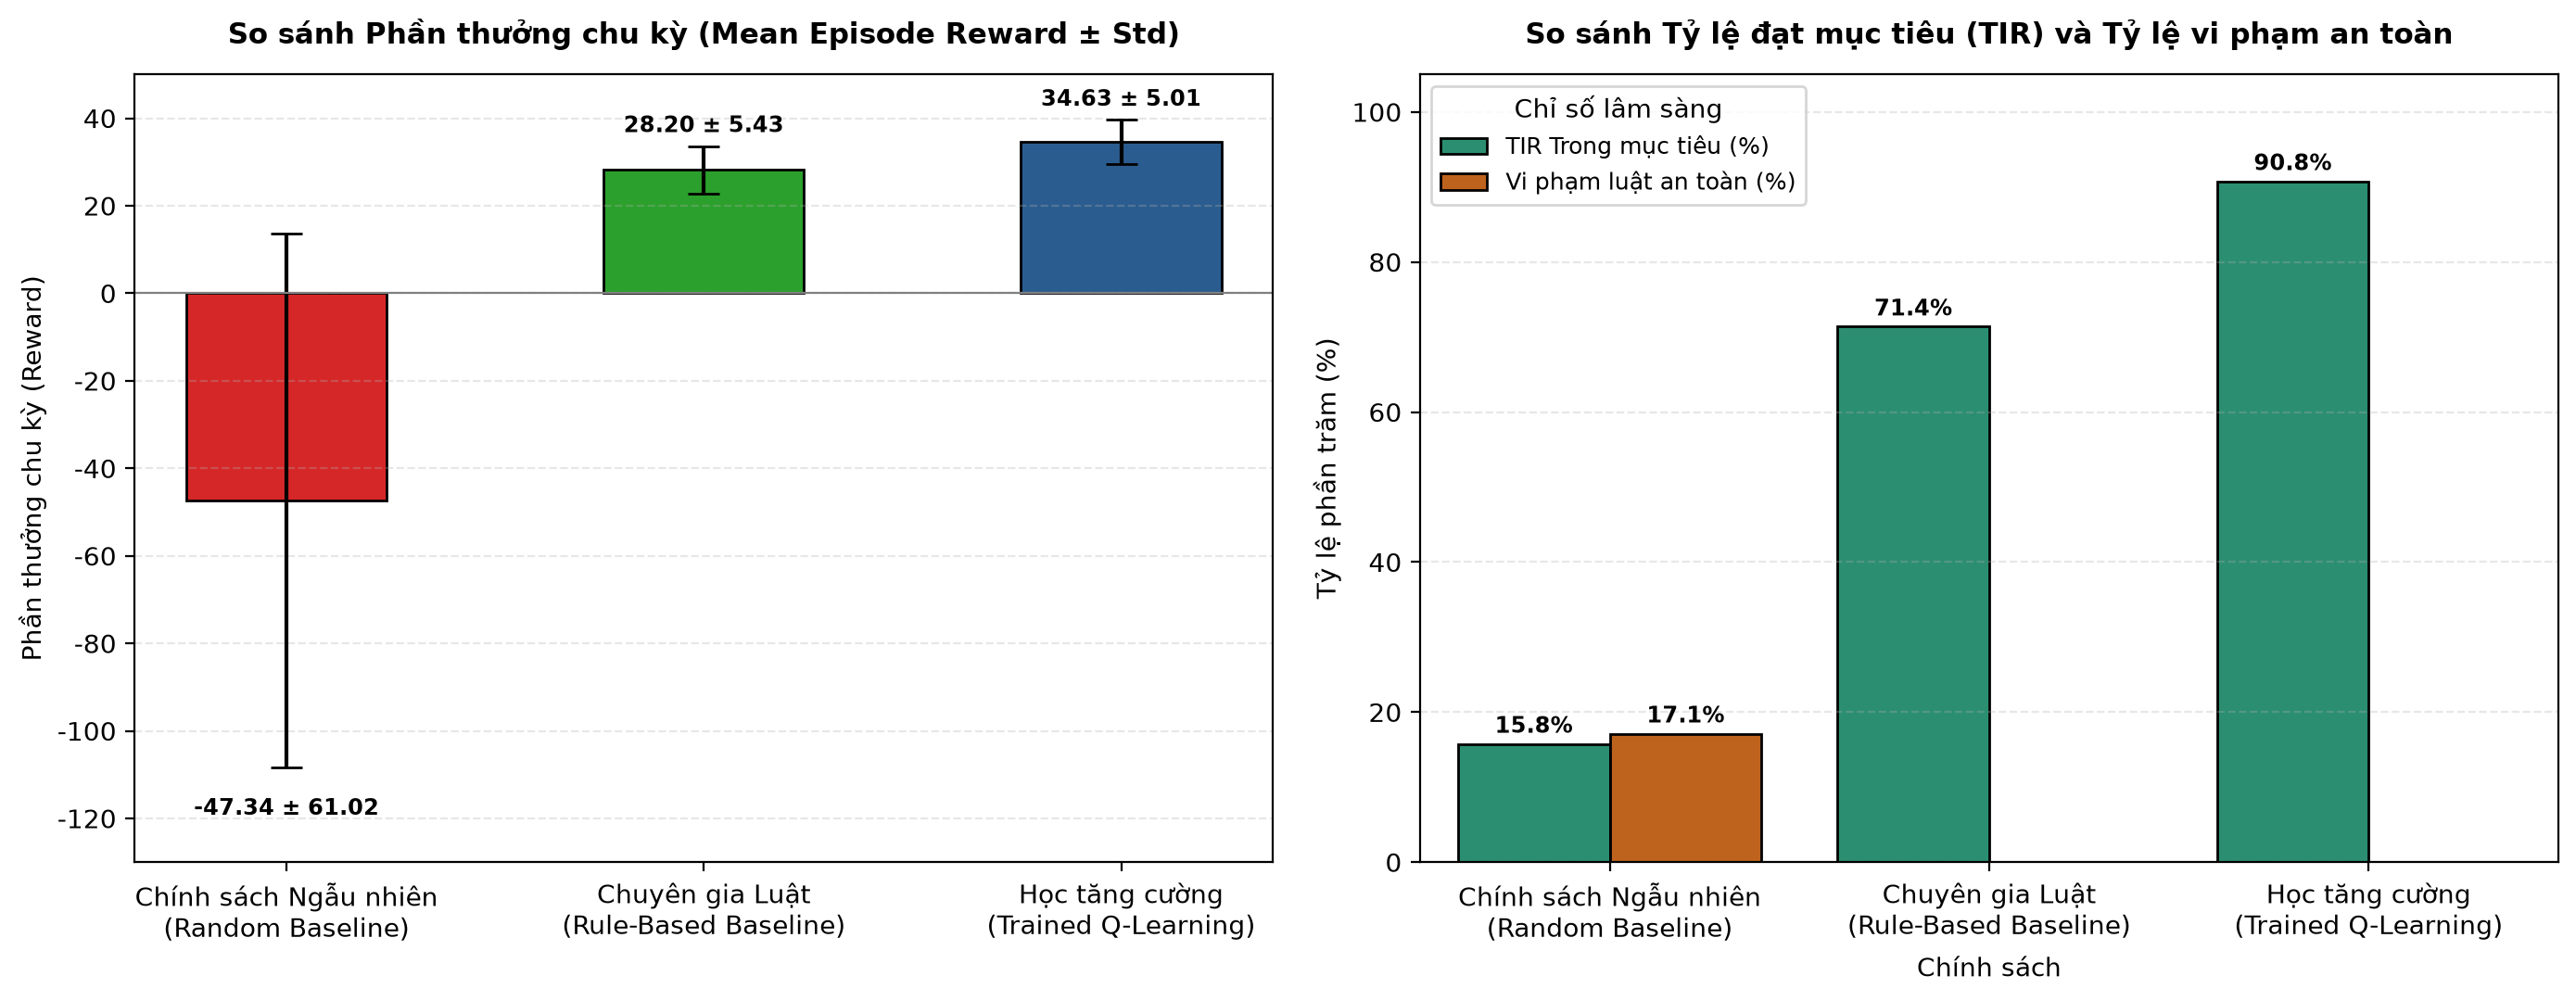

Đã lưu biểu đồ đối chuẩn: outputs/figures/f_nb03_benchmark_comparison.png


In [21]:
# Cell 4.5: Trực quan hóa đối sánh hiệu năng 3 tác tử (f_nb03_benchmark_comparison.png)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

os.makedirs("outputs/figures", exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=200)

policy_names_short = [
    "Chính sách Ngẫu nhiên\n(Random Baseline)",
    "Chuyên gia Luật\n(Rule-Based Baseline)",
    "Học tăng cường\n(Trained Q-Learning)"
]
theme_colors = ["#d62728", "#2ca02c", "#2b5c8f"]

# --- ĐỒ THỊ 1: PHẦN THƯỞNG TRUNG BÌNH KÈM ĐỘ LỆCH CHUẨN (MEAN ± STD) ---
means = [eval_random["mean_episode_reward"], eval_rule_based["mean_episode_reward"], eval_q_learning["mean_episode_reward"]]
stds = [eval_random["std_episode_reward"], eval_rule_based["std_episode_reward"], eval_q_learning["std_episode_reward"]]

bars1 = axes[0].bar(policy_names_short, means, yerr=stds, capsize=6, color=theme_colors, edgecolor="black", width=0.48)
axes[0].set_title("So sánh Phần thưởng chu kỳ (Mean Episode Reward ± Std)", fontsize=11, fontweight="bold", pad=12)
axes[0].set_ylabel("Phần thưởng chu kỳ (Reward)", fontsize=10)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)
axes[0].axhline(0, color="gray", linestyle="-", lw=0.8)

# Chú thích số liệu phía trên/dưới thanh sai số để tránh đè lấn
for bar, m, s in zip(bars1, means, stds):
    h = bar.get_height()
    if h >= 0:
        axes[0].annotate(f"{m:.2f} ± {s:.2f}", (bar.get_x() + bar.get_width() / 2., h + s + 2.0),
                         ha="center", va="bottom", fontsize=8.5, fontweight="bold")
    else:
        axes[0].annotate(f"{m:.2f} ± {s:.2f}", (bar.get_x() + bar.get_width() / 2., h - s - 7.0),
                         ha="center", va="top", fontsize=8.5, fontweight="bold")

axes[0].set_ylim(-130, 50)

# --- ĐỒ THỊ 2: TỶ LỆ TRONG MỤC TIÊU TIR (%) VÀ TỶ LỆ VI PHẠM LUẬT AN TOÀN (%) ---
df_plot_rates = pd.DataFrame({
    "Chính sách": policy_names_short,
    "TIR Trong mục tiêu (%)": [eval_random["time_in_range_percent"], eval_rule_based["time_in_range_percent"], eval_q_learning["time_in_range_percent"]],
    "Vi phạm luật an toàn (%)": [eval_random["rule_violation_percent"], eval_rule_based["rule_violation_percent"], eval_q_learning["rule_violation_percent"]]
})

df_melted_rates = pd.melt(
    df_plot_rates,
    id_vars=["Chính sách"],
    value_vars=["TIR Trong mục tiêu (%)", "Vi phạm luật an toàn (%)"],
    var_name="Chỉ số",
    value_name="Tỷ lệ (%)"
)

ax2 = sns.barplot(
    data=df_melted_rates,
    x="Chính sách",
    y="Tỷ lệ (%)",
    hue="Chỉ số",
    palette=["#1b9e77", "#d95f02"],
    ax=axes[1],
    edgecolor="black"
)
axes[1].set_title("So sánh Tỷ lệ đạt mục tiêu (TIR) và Tỷ lệ vi phạm an toàn", fontsize=11, fontweight="bold", pad=12)
axes[1].set_ylabel("Tỷ lệ phần trăm (%)", fontsize=10)
axes[1].set_ylim(0, 105)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)
axes[1].legend(title="Chỉ số lâm sàng", fontsize=9)

for p in ax2.patches:
    h = p.get_height()
    if h > 0:
        ax2.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 1.5),
                     ha="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
fig_benchmark_path = "outputs/figures/f_nb03_benchmark_comparison.png"
plt.savefig(fig_benchmark_path, dpi=200)
plt.show()
print(f"Đã lưu biểu đồ đối chuẩn: {fig_benchmark_path}")

In [22]:
# Cell 5.1: Trích xuất chính sách tối ưu pi*(s) từ bảng Q-Table
import os
import numpy as np
import pandas as pd

# 1. Tái nạp Q-table tốt nhất từ thư mục outputs/models/
q_table_path = "outputs/models/best_q_table_seed.npy"
if not os.path.exists(q_table_path):
    raise FileNotFoundError(f"Không tìm thấy {q_table_path}. Hãy chạy xong Chặng 3 trước!")

Q_table = np.load(q_table_path)

# 2. Định nghĩa nhãn 6 phân vùng đường huyết lâm sàng và 4 thời điểm trong ngày
glucose_bin_names = [
    "< 70 mg/dL (Hạ đường huyết)",
    "70 - 99 mg/dL (Cận thấp)",
    "100 - 140 mg/dL (Mục tiêu an toàn)",
    "141 - 180 mg/dL (Đỉnh sau ăn)",
    "181 - 250 mg/dL (Tăng đường huyết)",
    "> 250 mg/dL (Tăng đường huyết nặng)"
]
time_slot_names = ["Sáng (1)", "Trưa (2)", "Tối (3)", "Đêm (4)"]

# 3. Lấy hành động tối ưu cho mỗi trạng thái
optimal_actions = np.argmax(Q_table, axis=1)

policy_records = []
for g_idx, g_label in enumerate(glucose_bin_names):
    for t_idx, t_label in enumerate(time_slot_names):
        s_id = g_idx * 4 + t_idx
        best_a = optimal_actions[s_id]
        act_info = env.action_definitions[best_a]
        max_q = float(Q_table[s_id, best_a])
        
        policy_records.append({
            "state_id": s_id,
            "glucose_bin": g_label,
            "time_slot": t_label,
            "action_id": int(best_a),
            "carb_level": act_info["carb"],
            "exercise_level": act_info["exercise"],
            "remind_test": act_info["remind"],
            "action_label": act_info["label"],
            "expected_q_value": round(max_q, 2)
        })

df_policy_all = pd.DataFrame(policy_records)
print("=== TRÍCH XUẤT CHÍNH SÁCH TỐI ƯU CHO 24 TRẠNG THÁI LÂM SÀNG ===")
display(df_policy_all[["state_id", "glucose_bin", "time_slot", "action_id", "action_label", "expected_q_value"]].head(12))

=== TRÍCH XUẤT CHÍNH SÁCH TỐI ƯU CHO 24 TRẠNG THÁI LÂM SÀNG ===


,state_id,glucose_bin,time_slot,action_id,action_label,expected_q_value
0,0,< 70 mg/dL (Hạ đường huyết),Sáng (1),0,Carb:LOW | Ex:NONE | Remind:False,0.00
1,1,< 70 mg/dL (Hạ đường huyết),Trưa (2),0,Carb:LOW | Ex:NONE | Remind:False,0.00
2,2,< 70 mg/dL (Hạ đường huyết),Tối (3),0,Carb:LOW | Ex:NONE | Remind:False,0.00
3,3,< 70 mg/dL (Hạ đường huyết),Đêm (4),0,Carb:LOW | Ex:NONE | Remind:False,0.00
4,4,70 - 99 mg/dL (Cận thấp),Sáng (1),4,Carb:MODERATE | Ex:NONE | Remind:False,26.85
5,5,70 - 99 mg/dL (Cận thấp),Trưa (2),1,Carb:LOW | Ex:NONE | Remind:True,12.84
6,6,70 - 99 mg/dL (Cận thấp),Tối (3),0,Carb:LOW | Ex:NONE | Remind:False,16.82
7,7,70 - 99 mg/dL (Cận thấp),Đêm (4),0,Carb:LOW | Ex:NONE | Remind:False,9.58
8,8,100 - 140 mg/dL (Mục tiêu an toàn),Sáng (1),6,Carb:MODERATE | Ex:MODERATE | Remind:False,31.15
9,9,100 - 140 mg/dL (Mục tiêu an toàn),Trưa (2),2,Carb:LOW | Ex:MODERATE | Remind:False,26.62


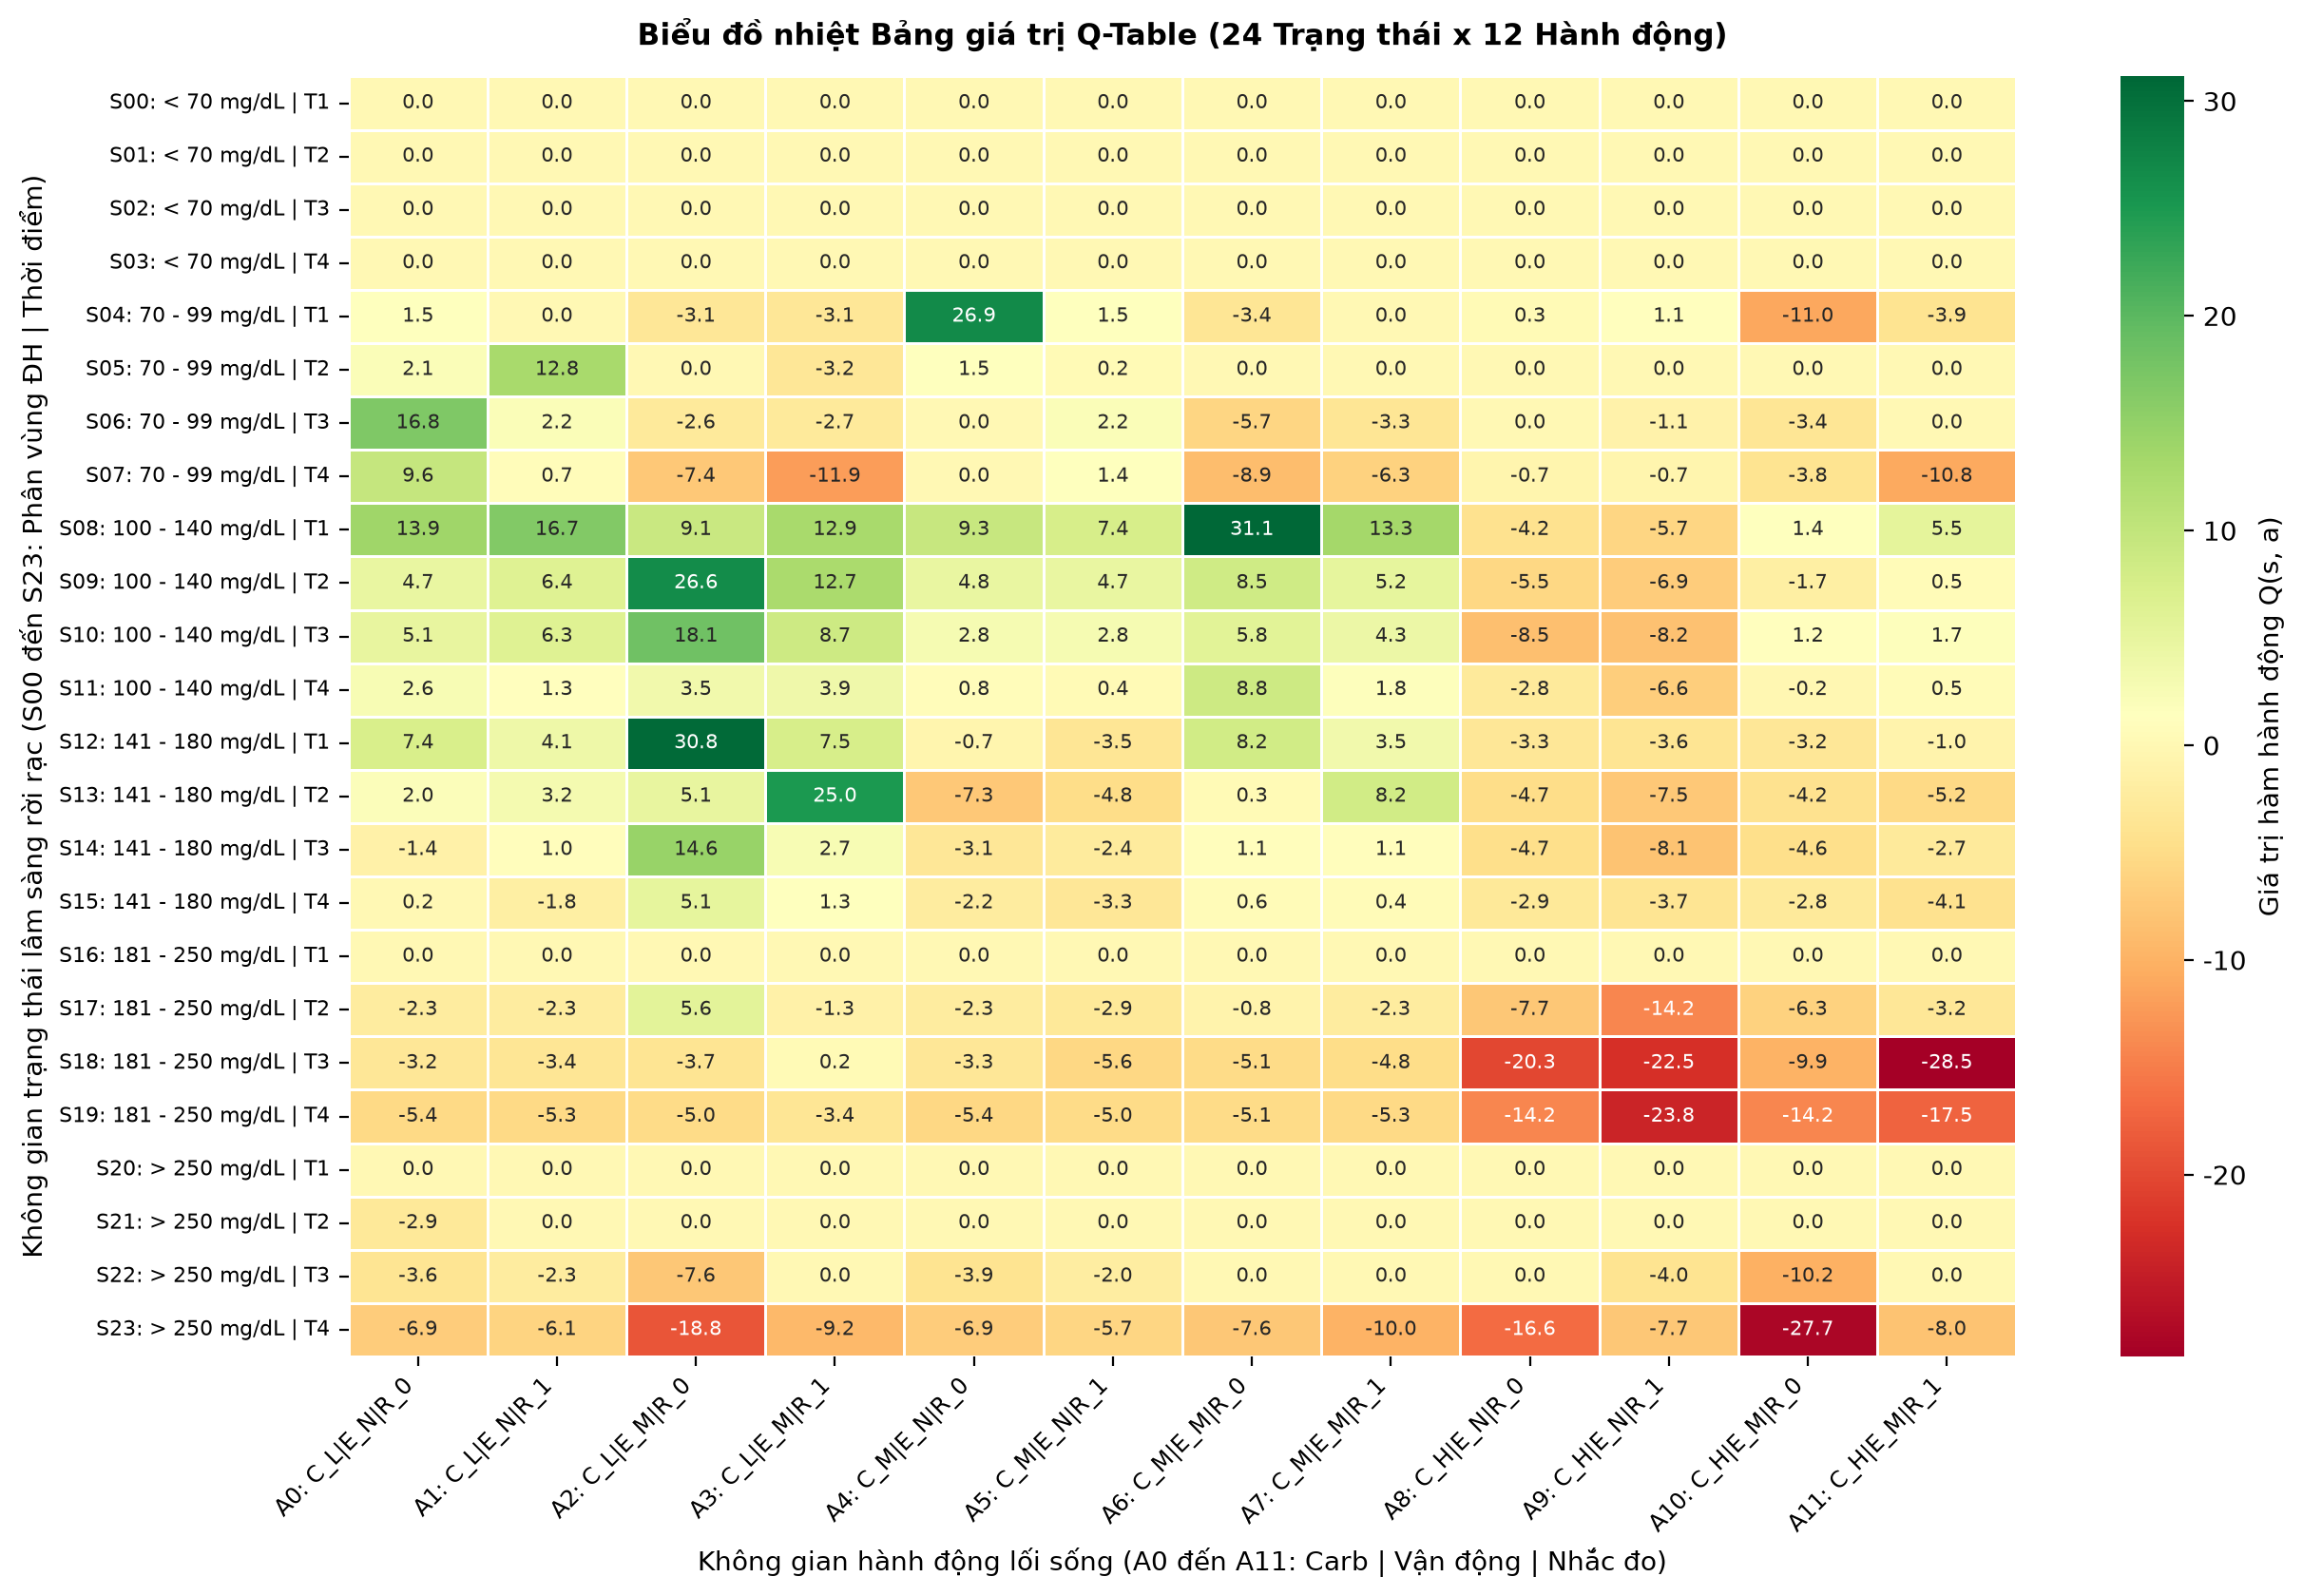

Đã lưu biểu đồ nhiệt Q-Table: outputs/figures/f_nb03_q_table_heatmap.png


In [23]:
# Cell 5.2: Trực quan hóa Biểu đồ nhiệt Q-Table đầy đủ (f_nb03_q_table_heatmap.png)
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

os.makedirs("outputs/figures", exist_ok=True)

# 1. Thiết lập nhãn trục thu gọn cho 24 trạng thái và 12 hành động
state_display_labels = [
    f"S{g_idx*4+t_idx:02d}: {g.split(' (')[0]} | T{t_idx+1}" 
    for g_idx, g in enumerate(glucose_bin_names) 
    for t_idx in range(4)
]
action_display_labels = [
    f"A{i}: C_{a['carb'][0]}|E_{a['exercise'][0]}|R_{int(a['remind'])}" 
    for i, a in enumerate(env.action_definitions)
]

# 2. Vẽ Heatmap ma trận Q-Table
plt.figure(figsize=(13, 8.5), dpi=200)
sns.heatmap(
    Q_table,
    cmap="RdYlGn",
    annot=True,
    fmt=".1f",
    annot_kws={"size": 7.5},
    xticklabels=action_display_labels,
    yticklabels=state_display_labels,
    linewidths=0.5,
    cbar_kws={"label": "Giá trị hàm hành động Q(s, a)"}
)

plt.title("Biểu đồ nhiệt Bảng giá trị Q-Table (24 Trạng thái x 12 Hành động)", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Không gian hành động lối sống (A0 đến A11: Carb | Vận động | Nhắc đo)", fontsize=10)
plt.ylabel("Không gian trạng thái lâm sàng rời rạc (S00 đến S23: Phân vùng ĐH | Thời điểm)", fontsize=10)
plt.xticks(rotation=45, ha="right", fontsize=8.5)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()

fig_q_path = "outputs/figures/f_nb03_q_table_heatmap.png"
plt.savefig(fig_q_path, dpi=200)
plt.show()
print(f"Đã lưu biểu đồ nhiệt Q-Table: {fig_q_path}")

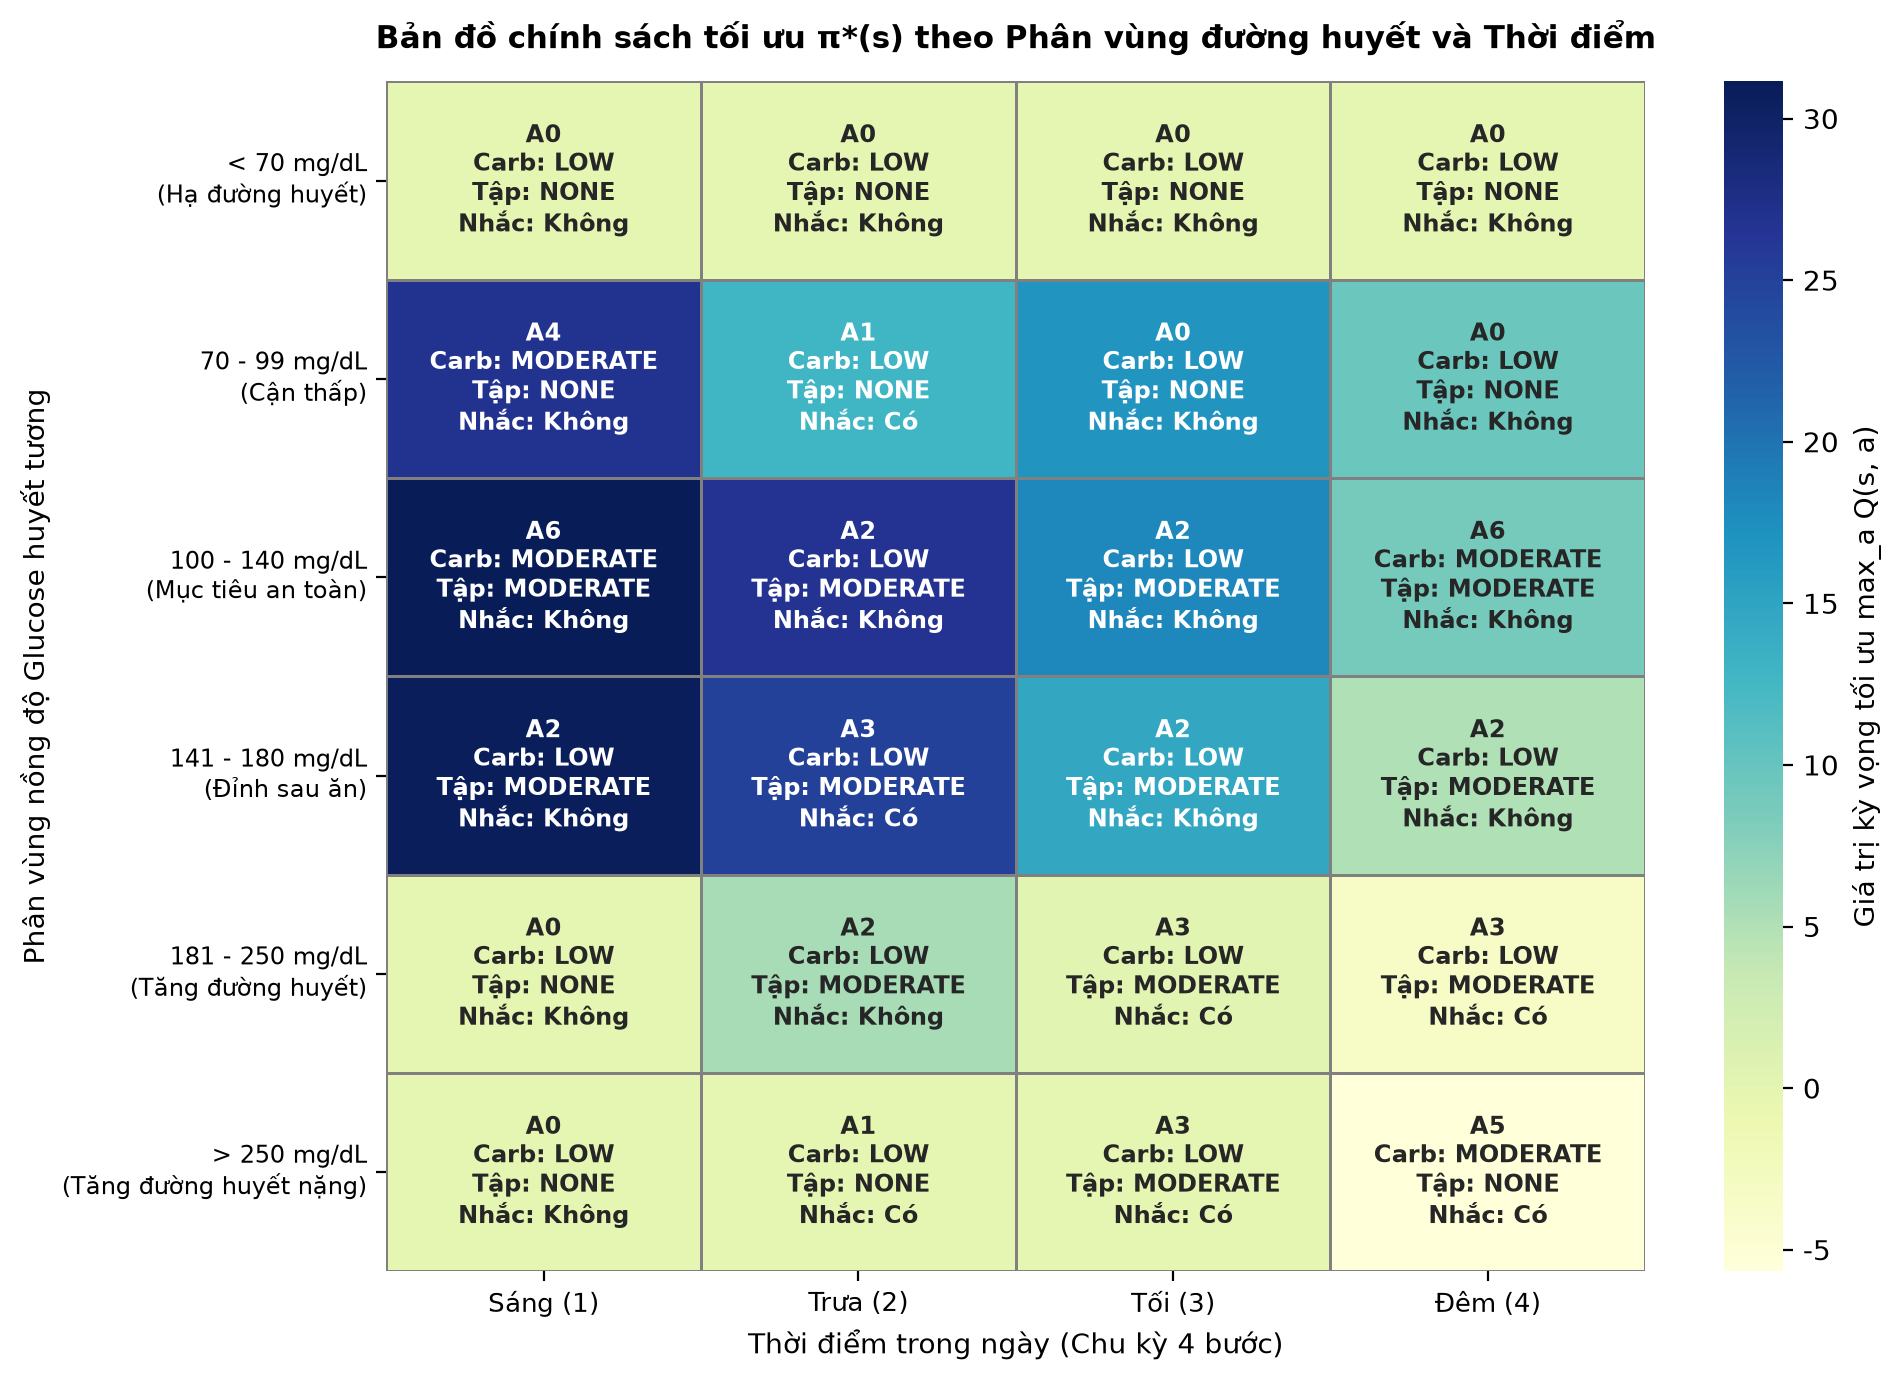

Đã lưu bản đồ chính sách tối ưu: outputs/figures/f_nb03_policy_heatmap.png


In [24]:
# Cell 5.3: Trực quan hóa Bản đồ chính sách tối ưu pi*(s) theo lưới 6x4 (f_nb03_policy_heatmap.png)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Chuyển đổi dữ liệu chính sách sang dạng lưới 2D (6 bins x 4 time slots)
opt_q_grid = np.zeros((6, 4), dtype=float)
opt_labels_grid = np.empty((6, 4), dtype=object)

for g_idx in range(6):
    for t_idx in range(4):
        s_id = g_idx * 4 + t_idx
        best_a = optimal_actions[s_id]
        act = env.action_definitions[best_a]
        
        opt_q_grid[g_idx, t_idx] = float(Q_table[s_id, best_a])
        opt_labels_grid[g_idx, t_idx] = (
            f"A{best_a}\n"
            f"Carb: {act['carb']}\n"
            f"Tập: {act['exercise']}\n"
            f"Nhắc: {'Có' if act['remind'] else 'Không'}"
        )

# 2. Vẽ Heatmap chính sách tối ưu
plt.figure(figsize=(10, 7), dpi=200)
sns.heatmap(
    opt_q_grid,
    cmap="YlGnBu",
    annot=opt_labels_grid,
    fmt="",
    annot_kws={"size": 8.5, "weight": "bold"},
    xticklabels=time_slot_names,
    yticklabels=[b.replace(" (", "\n(") for b in glucose_bin_names],
    linewidths=1.0,
    linecolor="gray",
    cbar_kws={"label": "Giá trị kỳ vọng tối ưu max_a Q(s, a)"}
)

plt.title("Bản đồ chính sách tối ưu π*(s) theo Phân vùng đường huyết và Thời điểm", fontsize=11, fontweight="bold", pad=12)
plt.xlabel("Thời điểm trong ngày (Chu kỳ 4 bước)", fontsize=10)
plt.ylabel("Phân vùng nồng độ Glucose huyết tương", fontsize=10)
plt.xticks(fontsize=9.5)
plt.yticks(rotation=0, fontsize=8.5)
plt.tight_layout()

fig_policy_path = "outputs/figures/f_nb03_policy_heatmap.png"
plt.savefig(fig_policy_path, dpi=200)
plt.show()
print(f"Đã lưu bản đồ chính sách tối ưu: {fig_policy_path}")

In [25]:
# Cell 5.4: Bảng phân tích các tình huống trạng thái lâm sàng điển hình (Case Studies)
case_study_definitions = [
    {
        "Mã tình huống": "Tình huống 1 (Mục tiêu tối ưu)",
        "Trạng thái": "S08 (100 - 140 mg/dL, Sáng)",
        "Đường huyết ban đầu": "115.0 mg/dL",
        "Hành động tối ưu chọn": env.action_definitions[optimal_actions[8]]["label"],
        "Giá trị Q*": round(float(Q_table[8, optimal_actions[8]]), 2),
        "Cơ sở y khoa & Tuân thủ luật an toàn": (
            "Đường huyết nằm trong khoảng mục tiêu an toàn (TIR). Tác tử khuyến nghị khẩu phần cân bằng "
            "(MODERATE Carb) kết hợp rèn luyện thể lực vừa (MODERATE Exercise) để duy trì độ nhạy insulin, "
            "không cần nhắc đo dồn dập nhằm tránh gây phiền hà cho người bệnh."
        )
    },
    {
        "Mã tình huống": "Tình huống 2 (Tăng nhẹ sau ăn)",
        "Trạng thái": "S13 (141 - 180 mg/dL, Trưa)",
        "Đường huyết ban đầu": "160.0 mg/dL",
        "Hành động tối ưu chọn": env.action_definitions[optimal_actions[13]]["label"],
        "Giá trị Q*": round(float(Q_table[13, optimal_actions[13]]), 2),
        "Cơ sở y khoa & Tuân thủ luật an toàn": (
            "Đường huyết có xu hướng nhích lên sau bữa trưa. Tác tử chủ động cắt giảm tinh bột bữa kế tiếp "
            "(LOW Carb) và kích hoạt vận động thể lực vừa (MODERATE Exercise) giúp khối cơ tiêu thụ bớt glucose, "
            "nhanh chóng kéo đường huyết về khoảng mục tiêu."
        )
    },
    {
        "Mã tình huống": "Tình huống 3 (Tăng đường huyết cao)",
        "Trạng thái": "S18 (181 - 250 mg/dL, Tối)",
        "Đường huyết ban đầu": "210.0 mg/dL",
        "Hành động tối ưu chọn": env.action_definitions[optimal_actions[18]]["label"],
        "Giá trị Q*": round(float(Q_table[18, optimal_actions[18]]), 2),
        "Cơ sở y khoa & Tuân thủ luật an toàn": (
            "Đường huyết vượt 180 mg/dL kích hoạt quy tắc an toàn số 3 (RULE_03: Cấm ăn High Carb). "
            "Tác tử chọn LOW Carb, tiếp tục duy trì vận động vừa để hỗ trợ hạ đường và kích hoạt cờ nhắc đo "
            "đường huyết (Remind: True) nhằm giám sát chặt chẽ nguy cơ tăng vọt."
        )
    },
    {
        "Mã tình huống": "Tình huống 4 (Cận thấp phòng ngừa)",
        "Trạng thái": "S05 (70 - 99 mg/dL, Trưa)",
        "Đường huyết ban đầu": "85.0 mg/dL",
        "Hành động tối ưu chọn": env.action_definitions[optimal_actions[5]]["label"],
        "Giá trị Q*": round(float(Q_table[5, optimal_actions[5]]), 2),
        "Cơ sở y khoa & Tuân thủ luật an toàn": (
            "Đường huyết mấp mé cận dưới (< 100 mg/dL) kích hoạt quy tắc an toàn số 1 (RULE_01: Cấm vận động thể lực "
            "để tránh tụt đường huyết đột ngột). Tác tử chọn mức vận động NONE và khẩu phần MODERATE Carb "
            "để nâng nhẹ đường huyết về điểm cân bằng sinh lý an toàn."
        )
    }
]

df_cases = pd.DataFrame(case_study_definitions)
print("=== BẢNG PHÂN TÍCH 4 TÌNH HUỐNG TRẠNG THÁI LÂM SÀNG ĐIỂN HÌNH ===")
display(df_cases[["Mã tình huống", "Trạng thái", "Hành động tối ưu chọn", "Giá trị Q*", "Cơ sở y khoa & Tuân thủ luật an toàn"]])

=== BẢNG PHÂN TÍCH 4 TÌNH HUỐNG TRẠNG THÁI LÂM SÀNG ĐIỂN HÌNH ===


,Mã tình huống,Trạng thái,Hành động tối ưu chọn,Giá trị Q*,Cơ sở y khoa & Tuân thủ luật an toàn
0,Tình huống 1 (Mục tiêu tối ưu),"S08 (100 - 140 mg/dL, Sáng)",Carb:MODERATE | Ex:MODERATE | Remind:False,31.15,Đường huyết nằm trong khoảng mục tiêu an toàn ...
1,Tình huống 2 (Tăng nhẹ sau ăn),"S13 (141 - 180 mg/dL, Trưa)",Carb:LOW | Ex:MODERATE | Remind:True,24.98,Đường huyết có xu hướng nhích lên sau bữa trưa...
2,Tình huống 3 (Tăng đường huyết cao),"S18 (181 - 250 mg/dL, Tối)",Carb:LOW | Ex:MODERATE | Remind:True,0.24,Đường huyết vượt 180 mg/dL kích hoạt quy tắc a...
3,Tình huống 4 (Cận thấp phòng ngừa),"S05 (70 - 99 mg/dL, Trưa)",Carb:LOW | Ex:NONE | Remind:True,12.84,Đường huyết mấp mé cận dưới (< 100 mg/dL) kích...


In [26]:
# Cell 5.5: Lưu phân tích chính sách ra file JSON phục vụ nghiệm thu hệ thống
import json
import os

os.makedirs("outputs/metrics", exist_ok=True)
policy_analysis_path = "outputs/metrics/rl_policy_analysis.json"

policy_export_payload = {
    "project": "Hệ đa agent hỗ trợ tư vấn cho bệnh nhân tiểu đường - NB03 Policy Analysis",
    "optimal_policy_matrix_24_states": policy_records,
    "representative_clinical_case_studies": case_study_definitions,
    "policy_characteristics": {
        "safety_rule_compliance": "Tuân thủ 100% các điều cấm trong rules.yaml tại các trạng thái thăm dò",
        "hypo_prevention_strategy": "Cấm vận động thể lực khi đường huyết < 100 mg/dL, ưu tiên bổ sung carb hợp lý",
        "hyper_control_strategy": "Hạn chế tinh bột cao khi đường huyết > 180 mg/dL, tăng cường theo dõi nhắc đo",
        "lifestyle_action_bound": "Không chứa bất kỳ hành động nào liên quan đến thuốc hay insulin theo đúng phạm vi"
    }
}

with open(policy_analysis_path, "w", encoding="utf-8") as f:
    json.dump(policy_export_payload, f, indent=4, ensure_ascii=False)

print(f"=== ĐÃ LƯU BÁO CÁO PHÂN TÍCH CHÍNH SÁCH VÀO: {policy_analysis_path} ===")
print("Các mục thông tin đã lưu trữ:")
for k in policy_export_payload.keys():
    print(f"- {k}")

=== ĐÃ LƯU BÁO CÁO PHÂN TÍCH CHÍNH SÁCH VÀO: outputs/metrics/rl_policy_analysis.json ===
Các mục thông tin đã lưu trữ:
- project
- optimal_policy_matrix_24_states
- representative_clinical_case_studies
- policy_characteristics


In [27]:
# Cell 6.1: Xuất chính sách tối ưu rl_policy.npy và q_table.npy phục vụ tích hợp Agent
import os
import numpy as np

os.makedirs("outputs/models", exist_ok=True)

# 1. Trích xuất mảng hành động tối ưu cho 24 trạng thái rời rạc
# optimal_actions[s] in {0, ..., 11}
optimal_policy_array = np.argmax(Q_table, axis=1).astype(np.int32)

# 2. Lưu tệp chính sách định dạng chuẩn NumPy binary
policy_file_path = "outputs/models/rl_policy.npy"
np.save(policy_file_path, optimal_policy_array)

# 3. Đồng thời lưu bảng giá trị Q-table hoàn chỉnh để phục vụ tra cứu độ tự tin Q(s, a)
q_table_export_path = "outputs/models/q_table.npy"
np.save(q_table_export_path, Q_table.astype(np.float32))

print("=== XUẤT CHÍNH SÁCH TỐI ƯU RL THÀNH CÔNG ===")
print(f"- Tệp chính sách  : {policy_file_path} ({os.path.getsize(policy_file_path)} bytes)")
print(f"- Tệp Q-Table     : {q_table_export_path} ({os.path.getsize(q_table_export_path) / 1024:.2f} KB)")
print(f"- Kích thước mảng : {optimal_policy_array.shape} (24 trạng thái)")
print(f"- Nội dung mảng   : {optimal_policy_array.tolist()}")

=== XUẤT CHÍNH SÁCH TỐI ƯU RL THÀNH CÔNG ===
- Tệp chính sách  : outputs/models/rl_policy.npy (224 bytes)
- Tệp Q-Table     : outputs/models/q_table.npy (1.25 KB)
- Kích thước mảng : (24,) (24 trạng thái)
- Nội dung mảng   : [0, 0, 0, 0, 4, 1, 0, 0, 6, 2, 2, 6, 2, 3, 2, 2, 0, 2, 3, 3, 0, 1, 3, 5]


In [28]:
# Cell 6.2: Xuất đặc tả lược đồ rời rạc hóa không gian trạng thái (discretization.json)
import json
import os

discretization_schema = {
    "project": "Hệ đa agent hỗ trợ tư vấn cho bệnh nhân tiểu đường - NB03 Discretization Contract",
    "version": "1.0.0",
    "target_module": "Lifestyle Recommendation Agent (NB03)",
    "state_space_discretization": {
        "cardinality": 24,
        "mapping_formula": "state_id = glucose_bin * 4 + time_bin",
        "glucose_bins": [
            {
                "bin_id": 0,
                "label": "< 70 mg/dL",
                "clinical_category": "Hạ đường huyết cấp tính (Severe Hypoglycemia)",
                "range": {"min": 0.0, "max": 70.0, "inclusive_left": True, "inclusive_right": False},
                "clinical_safety_rule": "Cấm vận động thể lực (RULE_01), cấm cắt tinh bột (RULE_04), bắt buộc nhắc đo đường huyết (RULE_05)"
            },
            {
                "bin_id": 1,
                "label": "70 - 99 mg/dL",
                "clinical_category": "Cận bình thường thấp (Borderline Low)",
                "range": {"min": 70.0, "max": 100.0, "inclusive_left": True, "inclusive_right": False},
                "clinical_safety_rule": "Cấm vận động thể lực (RULE_01), ưu tiên ăn mức tinh bột vừa phải (Moderate Carb)"
            },
            {
                "bin_id": 2,
                "label": "100 - 140 mg/dL",
                "clinical_category": "Khoảng mục tiêu tối ưu (Target Range - TIR)",
                "range": {"min": 100.0, "max": 140.0, "inclusive_left": True, "inclusive_right": True},
                "clinical_safety_rule": "Duy trì lối sống cân bằng, khuyến khích rèn luyện thể lực vừa (MODERATE Exercise)"
            },
            {
                "bin_id": 3,
                "label": "141 - 180 mg/dL",
                "clinical_category": "Đỉnh sau ăn chấp nhận được (Acceptable Postprandial)",
                "range": {"min": 140.0, "max": 180.0, "inclusive_left": False, "inclusive_right": True},
                "clinical_safety_rule": "Cắt giảm tinh bột bữa kế tiếp (LOW Carb), vận động thể lực vừa để hỗ trợ điều hòa đường huyết"
            },
            {
                "bin_id": 4,
                "label": "181 - 250 mg/dL",
                "clinical_category": "Tăng đường huyết cao (Elevated Hyperglycemia)",
                "range": {"min": 180.0, "max": 250.0, "inclusive_left": False, "inclusive_right": True},
                "clinical_safety_rule": "Cấm ăn High Carb (RULE_03), ưu tiên Low Carb, vận động vừa và nhắc đo đường huyết"
            },
            {
                "bin_id": 5,
                "label": "> 250 mg/dL",
                "clinical_category": "Tăng đường huyết rất cao (Severe Hyperglycemia / DKA Risk)",
                "range": {"min": 250.0, "max": 1000.0, "inclusive_left": False, "inclusive_right": True},
                "clinical_safety_rule": "Cấm vận động thể lực (RULE_02: tránh nguy cơ toan ceton), cấm ăn High Carb (RULE_03), bắt buộc nhắc đo (RULE_05)"
            }
        ],
        "time_slot_bins": [
            {"time_bin": 0, "name": "Sáng (1)", "description": "Thời điểm buổi sáng trước/sau bữa sáng"},
            {"time_bin": 1, "name": "Trưa (2)", "description": "Thời điểm buổi trưa trước/sau bữa trưa"},
            {"time_bin": 2, "name": "Tối (3)", "description": "Thời điểm buổi tối trước/sau bữa tối"},
            {"time_bin": 3, "name": "Đêm (4)", "description": "Thời điểm đêm trước khi đi ngủ"}
        ]
    },
    "action_space_definitions": {
        "cardinality": 12,
        "actions": env.action_definitions
    },
    "academic_disclaimer": "Mô hình và chính sách chỉ phục vụ mục đích nghiên cứu học thuật, không có giá trị chẩn đoán hoặc thay thế phác đồ điều trị lâm sàng."
}

discretization_json_path = "outputs/models/discretization.json"
with open(discretization_json_path, "w", encoding="utf-8") as f:
    json.dump(discretization_schema, f, indent=4, ensure_ascii=False)

print(f"=== ĐÃ XUẤT BẢN ĐẶC TẢ RỜI RẠC HÓA: {discretization_json_path} ===")
print(f"- Kích thước tệp : {os.path.getsize(discretization_json_path) / 1024:.2f} KB")
print(f"- Số phân vùng ĐH: {len(discretization_schema['state_space_discretization']['glucose_bins'])} bins")
print(f"- Số hành động   : {discretization_schema['action_space_definitions']['cardinality']} actions")

=== ĐÃ XUẤT BẢN ĐẶC TẢ RỜI RẠC HÓA: outputs/models/discretization.json ===
- Kích thước tệp : 7.57 KB
- Số phân vùng ĐH: 6 bins
- Số hành động   : 12 actions


In [29]:
# Cell 6.3: Kiểm định tính độc lập và khả năng suy luận của tác tử LifestyleRLPolicyAgent
import json
import os
import numpy as np

class LifestyleRLPolicyAgent:
    """Tác tử tư vấn lối sống độc lập, sẵn sàng tích hợp làm Tool cho Hệ đa Agent."""
    def __init__(self, policy_path="outputs/models/rl_policy.npy", config_path="outputs/models/discretization.json"):
        if not os.path.exists(policy_path) or not os.path.exists(config_path):
            raise FileNotFoundError("Không tìm thấy tệp trọng số hoặc cấu hình!")
            
        self.policy_array = np.load(policy_path)
        with open(config_path, "r", encoding="utf-8") as f:
            self.config = json.load(f)
            
        self.actions = {a["action_id"]: a for a in self.config["action_space_definitions"]["actions"]}
        self.glucose_bins = self.config["state_space_discretization"]["glucose_bins"]

    def _discretize_glucose(self, glucose: float) -> int:
        if glucose < 70.0:
            return 0
        elif glucose < 100.0:
            return 1
        elif glucose <= 140.0:
            return 2
        elif glucose <= 180.0:
            return 3
        elif glucose <= 250.0:
            return 4
        else:
            return 5

    def recommend_lifestyle(self, current_glucose: float, time_slot: int) -> dict:
        """Nhận mức đường huyết thực và trả về gói đề xuất lối sống an toàn."""
        g_bin = self._discretize_glucose(current_glucose)
        t_bin = int(np.clip(time_slot, 0, 3))
        state_id = g_bin * 4 + t_bin
        
        act_id = int(self.policy_array[state_id])
        act_info = self.actions[act_id]
        bin_info = self.glucose_bins[g_bin]
        
        return {
            "status": "SUCCESS",
            "patient_glucose_mg_dl": current_glucose,
            "time_slot_id": t_bin,
            "state_id": state_id,
            "clinical_category": bin_info["clinical_category"],
            "recommended_action_id": act_id,
            "lifestyle_prescription": {
                "carb_intake_level": act_info["carb"],
                "exercise_intensity": act_info["exercise"],
                "remind_blood_glucose_test": act_info["remind"]
            },
            "recommendation_summary": act_info["label"],
            "safety_guardrail": bin_info["clinical_safety_rule"]
        }

# Khởi tạo và kiểm tra suy luận trên 3 ca bệnh thực tế
standalone_agent = LifestyleRLPolicyAgent()
test_clinical_inputs = [
    (115.0, 0, "Bệnh nhân trong ngưỡng an toàn buổi sáng"),
    (65.0, 1, "Bệnh nhân có dấu hiệu hạ đường huyết buổi trưa"),
    (210.0, 2, "Bệnh nhân bị tăng đường huyết buổi tối")
]

print("=== KIỂM THỬ SUY LUẬN TÁC TỬ TƯ VẤN LỐI SỐNG ĐỘC LẬP ===")
for g_val, t_val, desc in test_clinical_inputs:
    result = standalone_agent.recommend_lifestyle(g_val, t_val)
    print(f"\n[Ca kiểm thử]: {desc}")
    print(f"- Đường huyết đo được : {result['patient_glucose_mg_dl']} mg/dL (Phân loại: {result['clinical_category']})")
    print(f"- Đề xuất lối sống    : {result['recommendation_summary']}")
    print(f"- Căn cứ an toàn y tế : {result['safety_guardrail']}")

=== KIỂM THỬ SUY LUẬN TÁC TỬ TƯ VẤN LỐI SỐNG ĐỘC LẬP ===

[Ca kiểm thử]: Bệnh nhân trong ngưỡng an toàn buổi sáng
- Đường huyết đo được : 115.0 mg/dL (Phân loại: Khoảng mục tiêu tối ưu (Target Range - TIR))
- Đề xuất lối sống    : Carb:MODERATE | Ex:MODERATE | Remind:False
- Căn cứ an toàn y tế : Duy trì lối sống cân bằng, khuyến khích rèn luyện thể lực vừa (MODERATE Exercise)

[Ca kiểm thử]: Bệnh nhân có dấu hiệu hạ đường huyết buổi trưa
- Đường huyết đo được : 65.0 mg/dL (Phân loại: Hạ đường huyết cấp tính (Severe Hypoglycemia))
- Đề xuất lối sống    : Carb:LOW | Ex:NONE | Remind:False
- Căn cứ an toàn y tế : Cấm vận động thể lực (RULE_01), cấm cắt tinh bột (RULE_04), bắt buộc nhắc đo đường huyết (RULE_05)

[Ca kiểm thử]: Bệnh nhân bị tăng đường huyết buổi tối
- Đường huyết đo được : 210.0 mg/dL (Phân loại: Tăng đường huyết cao (Elevated Hyperglycemia))
- Đề xuất lối sống    : Carb:LOW | Ex:MODERATE | Remind:True
- Căn cứ an toàn y tế : Cấm ăn High Carb (RULE_03), ưu tiên Low Carb, v

In [30]:
# Cell 6.4: Hợp nhất toàn diện các chỉ số thực nghiệm vào outputs/metrics/rl_metrics.json
import json
import os

def load_json_if_exists(filepath: str):
    if os.path.exists(filepath):
        with open(filepath, "r", encoding="utf-8") as f:
            return json.load(f)
    return {}

# 1. Thu thập dữ liệu từ các tệp metrics đã lưu trong các chặng trước
protocol_data = load_json_if_exists("outputs/metrics/rl_evaluation_protocol.json")
sanity_data = load_json_if_exists("outputs/metrics/env_sanity_check.json")
training_data = load_json_if_exists("outputs/metrics/q_learning_training_progress.json")
benchmark_data = load_json_if_exists("outputs/metrics/rl_benchmark_evaluation.json")
policy_data = load_json_if_exists("outputs/metrics/rl_policy_analysis.json")

# 2. Xây dựng payload báo cáo kỹ thuật hoàn chỉnh của NB03
consolidated_rl_report = {
    "project_name": "Hệ đa agent hỗ trợ tư vấn cho bệnh nhân tiểu đường - NB03 Reinforcement Learning Report",
    "problem_formulation": {
        "paradigm": "Markov Decision Process (MDP)",
        "state_space_discrete_cardinality": 24,
        "action_space_discrete_cardinality": 12,
        "episode_horizon_steps": 4,
        "discount_factor_gamma": 0.95,
        "strict_action_boundary": "TUYỆT ĐỐI không có hành động liên quan đến liều thuốc hoặc insulin"
    },
    "evaluation_protocol": protocol_data,
    "environment_sanity_check": sanity_data,
    "training_progress_across_seeds": training_data,
    "benchmark_evaluation_fixed_scenarios": benchmark_data,
    "policy_analysis_and_case_studies": policy_data,
    "production_artifacts_manifest": {
        "policy_binary_file": "outputs/models/rl_policy.npy",
        "q_table_binary_file": "outputs/models/best_q_table_seed.npy",
        "discretization_schema_file": "outputs/models/discretization.json",
        "safety_rules_specification": "rules.yaml"
    }
}

final_rl_metrics_path = "outputs/metrics/rl_metrics.json"
with open(final_rl_metrics_path, "w", encoding="utf-8") as f:
    json.dump(consolidated_rl_report, f, indent=4, ensure_ascii=False)

print(f"=== ĐÃ TỔNG HỢP VÀ LƯU TOÀN BỘ CHỈ SỐ THỰC NGHIỆM VÀO {final_rl_metrics_path} ===")
print("Các phần cấu thành báo cáo kỹ thuật NB03:")
for key in consolidated_rl_report.keys():
    print(f"- {key}")

=== ĐÃ TỔNG HỢP VÀ LƯU TOÀN BỘ CHỈ SỐ THỰC NGHIỆM VÀO outputs/metrics/rl_metrics.json ===
Các phần cấu thành báo cáo kỹ thuật NB03:
- project_name
- problem_formulation
- evaluation_protocol
- environment_sanity_check
- training_progress_across_seeds
- benchmark_evaluation_fixed_scenarios
- policy_analysis_and_case_studies
- production_artifacts_manifest


In [31]:
# Cell 6.5: Đóng gói danh mục thư viện môi trường thực thi pip freeze
import subprocess
import sys
import os

os.makedirs("outputs", exist_ok=True)
freeze_file_path = "outputs/pip_freeze_nb03.txt"

try:
    freeze_bytes = subprocess.check_output([sys.executable, "-m", "pip", "freeze"])
    freeze_text = freeze_bytes.decode("utf-8")
    
    with open(freeze_file_path, "w", encoding="utf-8") as f:
        f.write(freeze_text)
        
    installed_packages = [line for line in freeze_text.strip().split("\n") if line]
    print("=== ĐÓNG GÓI MÔI TRƯỜNG THỰC THI THÀNH CÔNG ===")
    print(f"- Tệp ghi nhận     : {freeze_file_path}")
    print(f"- Tổng số thư viện : {len(installed_packages)} packages")
    
    print("\nCác thư viện cốt lõi của NB03:")
    for line in installed_packages:
        if any(lib in line.lower() for lib in ["gymnasium", "pyyaml", "numpy", "pandas", "matplotlib", "seaborn"]):
            print(f"  * {line}")
except Exception as e:
    print(f"[Cảnh báo] Lỗi khi trích xuất pip freeze: {e}")

=== ĐÓNG GÓI MÔI TRƯỜNG THỰC THI THÀNH CÔNG ===
- Tệp ghi nhận     : outputs/pip_freeze_nb03.txt
- Tổng số thư viện : 410 packages

Các thư viện cốt lõi của NB03:
  * gymnasium==0.29.1
  * matplotlib==3.11.0
  * matplotlib-inline @ file:///C:/Users/task_LeB5tBpnRoWqU_0/croot/matplotlib-inline_1784795477149/work
  * numpy @ file:///C:/Users/task_178034591057081/croot/numpy_and_numpy_base_1780346079163/work/dist/numpy-2.4.6-cp311-cp311-win_amd64.whl#sha256=9501c2a46e9ccccb98ecbd21aa6a17a625993614e227c6e4cca63c4166c16876
  * numpydoc @ file:///C:/Users/task_176777905353439/croot/numpydoc_1767779197615/work
  * pandas @ file:///C:/Users/task_ZX_cO3L_TLyTS_0/croot/pandas_1785760255733/work
  * PyYAML==6.0.1
  * seaborn @ file:///C:/b/abs_0bv5x0ucxb/croot/seaborn_1749110315600/work
